<a href="https://colab.research.google.com/github/vanessapeterka/a-sigla/blob/main/Vanessa_Aula_2_Series%20temporais.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Bibliotecas
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from datetime import timedelta
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


In [2]:
# 2. Períodos e identificadores (UTC; limite final exclusivo)

# DHN 304 — sete dias completos: 20/10 00:00 até 27/10 00:00
ID_DHN = 304
inicio_dhn = pd.Timestamp("2026-10-20 00:00:00", tz="UTC")
fim_dhn = pd.Timestamp("2026-10-27 00:00:00", tz="UTC")

# RJ-4 — quatorze dias: 20/10 00:00 até 03/11 00:00
ID_RJ4 = 12
inicio_vento = pd.Timestamp("2026-10-20 00:00:00", tz="UTC")
fim_vento = pd.Timestamp("2026-11-03 00:00:00", tz="UTC")

print("DHN 304:", inicio_dhn, "a", fim_dhn, "| duração:", fim_dhn-inicio_dhn)
print("RJ-4:", inicio_vento, "a", fim_vento, "| duração:", fim_vento-inicio_vento)

DHN 304: 2026-10-20 00:00:00+00:00 a 2026-10-27 00:00:00+00:00 | duração: 7 days 00:00:00
RJ-4: 2026-10-20 00:00:00+00:00 a 2026-11-03 00:00:00+00:00 | duração: 14 days 00:00:00


In [3]:
# 3. Função auxiliar para consultar API e converter timestamps para UTC

def resposta_em_registros(conteudo):
    if isinstance(conteudo, list):
        return conteudo
    if isinstance(conteudo, dict):
        for chave in ("data", "results", "result"):
            if isinstance(conteudo.get(chave), list):
                return conteudo[chave]
        return [conteudo] if conteudo else []
    return []

def consultar_api(endpoint, boia_id, inicio, fim, parametros):
    url = f"https://simcosta.furg.br/api/{endpoint}"
    params = {
        "boiaID": boia_id,
        "type": "json",
        "time1": int(inicio.timestamp()),
        "time2": int(fim.timestamp()),
        "params": ",".join(parametros)
    }
    r = requests.get(url, params=params, timeout=120)
    print(endpoint, "| HTTP", r.status_code)
    r.raise_for_status()
    registros = resposta_em_registros(r.json())
    if not registros:
        raise ValueError(f"A API {endpoint} não retornou registros no período.")
    dados = pd.json_normalize(registros)

    if "timestamp" in dados.columns:
        dados["timestamp"] = pd.to_datetime(dados["timestamp"], utc=True, errors="coerce")
    else:
        partes = ["YEAR", "MONTH", "DAY", "HOUR", "MINUTE", "SECOND"]
        if not all(c in dados.columns for c in partes):
            raise ValueError(f"Sem timestamp ou componentes de data/hora. Colunas: {dados.columns.tolist()}")
        tmp = dados[partes].copy()
        tmp.columns = ["year", "month", "day", "hour", "minute", "second"]
        dados["timestamp"] = pd.to_datetime(tmp, utc=True, errors="coerce")

    dados = dados.dropna(subset=["timestamp"])
    dados = dados.drop(columns=["YEAR", "MONTH", "DAY", "HOUR", "MINUTE", "SECOND"], errors="ignore")
    dados = dados[(dados["timestamp"] >= inicio) & (dados["timestamp"] < fim)]
    dados = dados.sort_values("timestamp").drop_duplicates("timestamp", keep="last")
    dados = dados.set_index("timestamp")
    for c in dados.columns:
        dados[c] = pd.to_numeric(dados[c], errors="coerce")
    return dados

print("Função de consulta definida.")

Função de consulta definida.


In [4]:
# 4. Extração do marégrafo DHN 304
parametros_dhn = [
    "avg_water_level_arbitrary_zero",
    "water_level_arbitrary_zero",
    "water_distance_instrument_zero",
    "avg_water_distance_instrument_zero"
]

df_dhn = consultar_api(
    endpoint="intrans_data",
    boia_id=ID_DHN,
    inicio=inicio_dhn,
    fim=fim_dhn,
    parametros=parametros_dhn
)

print("Registros DHN:", len(df_dhn))
print("Colunas:", df_dhn.columns.tolist())
display(df_dhn.head())

intrans_data | HTTP 200
Registros DHN: 9992
Colunas: ['water_level_arbitrary_zero', 'avg_water_level_arbitrary_zero', 'water_distance_instrument_zero', 'avg_water_distance_instrument_zero']


,water_level_arbitrary_zero,avg_water_level_arbitrary_zero,water_distance_instrument_zero,avg_water_distance_instrument_zero
timestamp,,,,
2026-10-20 00:00:00+00:00,12.579,12.590,2.421,2.410
2026-10-20 00:01:00+00:00,12.582,12.579,2.418,2.421
2026-10-20 00:02:00+00:00,12.574,12.587,2.426,2.413
2026-10-20 00:03:00+00:00,12.585,12.567,2.415,2.433
2026-10-20 00:04:00+00:00,12.552,12.580,2.448,2.420


In [5]:
# 5. Extração da velocidade do vento da boia RJ-4
# Os nomes abaixo são os parâmetros usados no seu Vanessa_ex02.ipynb.
parametros_met = [
    "Average_wind_speed",
    "Average_wind_direction_N",
    "Last_sampling_interval_gust_speed"
]

df_met = consultar_api(
    endpoint="metereo_data",
    boia_id=ID_RJ4,
    inicio=inicio_vento,
    fim=fim_vento,
    parametros=parametros_met
)

print("Registros meteorológicos RJ-4:", len(df_met))
print("Colunas retornadas:", df_met.columns.tolist())
display(df_met.head())

# Na resposta observada no seu notebook, os nomes de saída foram:
# Avg_Wnd_Sp (velocidade média), Avg_Wnd_Dir_N (direção), Gust_Sp (rajada).
# Interrompe com mensagem clara se o nome principal não vier.
if "Avg_Wnd_Sp" not in df_met.columns:
    raise KeyError("A API não retornou Avg_Wnd_Sp. Confira as colunas acima e ajuste o nome da variável.")

metereo_data | HTTP 200
Registros meteorológicos RJ-4: 576
Colunas retornadas: ['Avg_Wnd_Dir_N', 'Avg_Wnd_Sp', 'Gust_Sp', 'Avg_Wnd_Dir', 'M_Decl']


,Avg_Wnd_Dir_N,Avg_Wnd_Sp,Gust_Sp,Avg_Wnd_Dir,M_Decl
timestamp,,,,,
2026-10-20 00:21:00+00:00,40.99,4.6,6.8,64.0,-23.01
2026-10-20 00:51:00+00:00,23.99,4.2,5.9,47.0,-23.01
2026-10-20 01:21:00+00:00,32.99,5.5,6.9,56.0,-23.01
2026-10-20 01:51:00+00:00,20.99,4.5,6.1,44.0,-23.01
2026-10-20 02:21:00+00:00,16.99,4.5,6.5,40.0,-23.01


In [6]:
# 6. Construção das grades temporais e diagnóstico das lacunas

# Marégrafo: grade de 1 minuto exatamente no recorte de 7 dias
grade_dhn = pd.date_range(
    start=inicio_dhn, end=fim_dhn - pd.Timedelta(minutes=1), freq="1min"
)
nivel_obs = df_dhn["avg_water_level_arbitrary_zero"].reindex(grade_dhn)

# Vento: grade de 30 minutos. A série da RJ-4 costuma ter timestamp deslocado
# (por exemplo, minuto :21); preservamos essa fase temporal em vez de arredondar
# os timestamps para :00. A fase é inferida pelo primeiro timestamp observado.
passo_vento = pd.Timedelta(minutes=30)
if df_met.empty:
    raise ValueError("A série meteorológica RJ-4 está vazia.")
fase_vento = df_met.index[0] - df_met.index[0].floor("30min")
inicio_grade_vento = inicio_vento + fase_vento
grade_vento = pd.date_range(
    start=inicio_grade_vento,
    end=fim_vento - passo_vento + fase_vento,
    freq=passo_vento
)
vento_obs = df_met["Avg_Wnd_Sp"].reindex(grade_vento)

print("DHN — pontos esperados:", len(grade_dhn),
      "| válidos:", int(nivel_obs.count()),
      "| ausentes:", int(nivel_obs.isna().sum()))
print("RJ-4 — pontos esperados na grade:", len(grade_vento),
      "| válidos:", int(vento_obs.count()),
      "| ausentes:", int(vento_obs.isna().sum()))
print("Fase temporal RJ-4:", fase_vento)

# Verificar duplicados e passo modal nos timestamps recebidos
for nome, idx in [("DHN 304", df_dhn.index), ("RJ-4 vento", df_met.index)]:
    dif = idx.to_series().diff().dropna()
    print(f"\n{nome}: duplicados={idx.duplicated().sum()}")
    if len(dif):
        print("Passo modal:", dif.mode().iloc[0])
        print("Intervalo mínimo/máximo:", dif.min(), "/", dif.max())

DHN — pontos esperados: 10080 | válidos: 9990 | ausentes: 90
RJ-4 — pontos esperados na grade: 672 | válidos: 576 | ausentes: 96
Fase temporal RJ-4: 0 days 00:21:00

DHN 304: duplicados=0
Passo modal: 0 days 00:01:00
Intervalo mínimo/máximo: 0 days 00:01:00 / 0 days 00:02:00

RJ-4 vento: duplicados=0
Passo modal: 0 days 00:30:00
Intervalo mínimo/máximo: 0 days 00:30:00 / 0 days 13:00:00


In [7]:
# 7. Função para identificar lacunas como sequências de pontos ausentes

def tabela_lacunas(serie, passo):
    ausente = serie.isna()
    grupos = ausente.ne(ausente.shift()).cumsum()
    linhas = []
    for _, trecho in serie[ausente].groupby(grupos[ausente]):
        inicio = trecho.index[0]
        fim = trecho.index[-1]
        n = len(trecho)
        linhas.append({
            "inicio_UTC": inicio,
            "fim_UTC": fim,
            "pontos_ausentes": n,
            "duracao_sem_dado": n * passo
        })
    return pd.DataFrame(linhas)

lacunas_dhn = tabela_lacunas(nivel_obs, pd.Timedelta(minutes=1))
lacunas_vento = tabela_lacunas(vento_obs, passo_vento)

def resumo_serie(nome, serie, grade, passo, lacunas):
    validos = serie.dropna()
    total = len(grade)
    nvalidos = len(validos)
    maior = lacunas["duracao_sem_dado"].max() if not lacunas.empty else pd.Timedelta(0)
    resumo = {
        "Série": nome,
        "N esperado": total,
        "N válido": nvalidos,
        "N ausente": total - nvalidos,
        "Cobertura (%)": 100*nvalidos/total if total else np.nan,
        "Média": validos.mean(),
        "Desvio padrão amostral": validos.std(),
        "Passo": passo,
        "Nº de lacunas": len(lacunas),
        "Maior lacuna sem dado": maior,
        "Nyquist (período mínimo teórico)": 2*passo
    }
    return resumo

resumo_dhn = resumo_serie("Nível DHN 304 (m)", nivel_obs, grade_dhn,
                          pd.Timedelta(minutes=1), lacunas_dhn)
resumo_vento = resumo_serie("Velocidade do vento RJ-4 (m/s)", vento_obs, grade_vento,
                            passo_vento, lacunas_vento)

tabela_resumo = pd.DataFrame([resumo_dhn, resumo_vento])
display(tabela_resumo)
print("\nMaiores lacunas — DHN 304")
display(lacunas_dhn.sort_values("duracao_sem_dado", ascending=False).head(15))
print("\nMaiores lacunas — RJ-4")
display(lacunas_vento.sort_values("duracao_sem_dado", ascending=False).head(15))

,Série,N esperado,N válido,N ausente,Cobertura (%),Média,Desvio padrão amostral,Passo,Nº de lacunas,Maior lacuna sem dado,Nyquist (período mínimo teórico)
0,Nível DHN 304 (m),10080,9990,90,99.107143,12.172060,0.371166,0 days 00:01:00,90,0 days 00:01:00,0 days 00:02:00
1,Velocidade do vento RJ-4 (m/s),672,576,96,85.714286,4.078819,2.300012,0 days 00:30:00,41,0 days 12:30:00,0 days 01:00:00



Maiores lacunas — DHN 304


,inicio_UTC,fim_UTC,pontos_ausentes,duracao_sem_dado
0,2026-10-20 01:37:00+00:00,2026-10-20 01:37:00+00:00,1,0 days 00:01:00
67,2026-10-25 02:47:00+00:00,2026-10-25 02:47:00+00:00,1,0 days 00:01:00
65,2026-10-25 01:32:00+00:00,2026-10-25 01:32:00+00:00,1,0 days 00:01:00
64,2026-10-24 16:18:00+00:00,2026-10-24 16:18:00+00:00,1,0 days 00:01:00
63,2026-10-24 14:47:00+00:00,2026-10-24 14:47:00+00:00,1,0 days 00:01:00
62,2026-10-24 13:34:00+00:00,2026-10-24 13:34:00+00:00,1,0 days 00:01:00
61,2026-10-24 12:47:00+00:00,2026-10-24 12:47:00+00:00,1,0 days 00:01:00
60,2026-10-24 12:04:00+00:00,2026-10-24 12:04:00+00:00,1,0 days 00:01:00
59,2026-10-24 08:18:00+00:00,2026-10-24 08:18:00+00:00,1,0 days 00:01:00
58,2026-10-24 07:48:00+00:00,2026-10-24 07:48:00+00:00,1,0 days 00:01:00



Maiores lacunas — RJ-4


,inicio_UTC,fim_UTC,pontos_ausentes,duracao_sem_dado
6,2026-10-22 11:51:00+00:00,2026-10-22 23:51:00+00:00,25,0 days 12:30:00
9,2026-10-23 11:51:00+00:00,2026-10-23 23:51:00+00:00,25,0 days 12:30:00
21,2026-10-29 05:21:00+00:00,2026-10-29 06:21:00+00:00,3,0 days 01:30:00
31,2026-10-31 06:21:00+00:00,2026-10-31 07:21:00+00:00,3,0 days 01:30:00
0,2026-10-20 08:51:00+00:00,2026-10-20 09:21:00+00:00,2,0 days 01:00:00
32,2026-10-31 08:21:00+00:00,2026-10-31 08:51:00+00:00,2,0 days 01:00:00
38,2026-11-02 07:51:00+00:00,2026-11-02 08:21:00+00:00,2,0 days 01:00:00
29,2026-10-30 23:51:00+00:00,2026-10-30 23:51:00+00:00,1,0 days 00:30:00
23,2026-10-29 18:51:00+00:00,2026-10-29 18:51:00+00:00,1,0 days 00:30:00
24,2026-10-29 21:51:00+00:00,2026-10-29 21:51:00+00:00,1,0 days 00:30:00


Foram gerados gráficos de linha independentes para o nível observado do marégrafo DHN 304 e para a velocidade do vento da boia RJ-4 utilizando o eixo de tempo correto em UTC. Como os dados foram reindexados em grades regulares com valores ausentes representados por NaN (nivel_obs e vento_obs), o Matplotlib deixa as lacunas visíveis de forma explícita na linha contínua do gráfico.

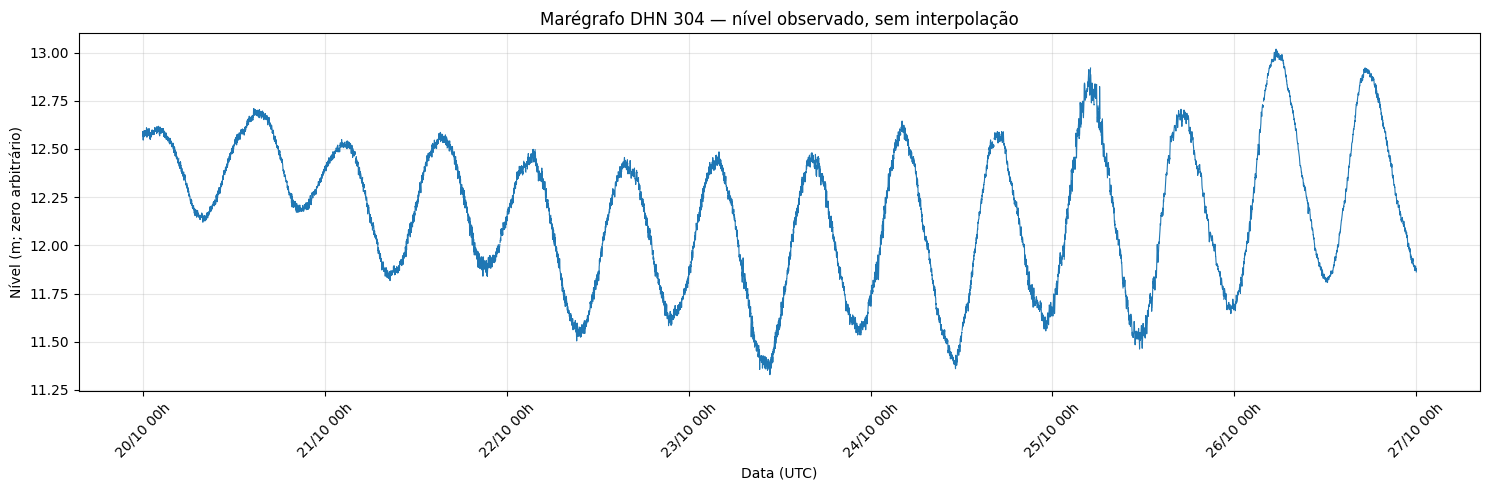

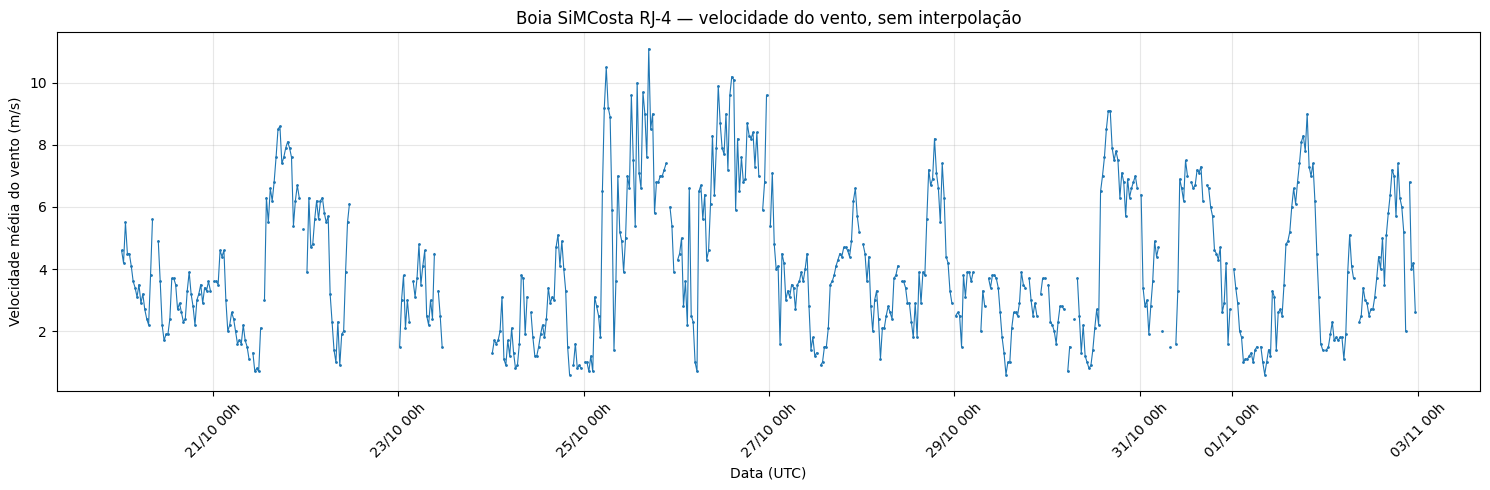

In [9]:
# 8. Gráficos das séries originais — sem preencher lacunas
from datetime import timezone

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(nivel_obs.index, nivel_obs, lw=0.8)
ax.set_title("Marégrafo DHN 304 — nível observado, sem interpolação")
ax.set_ylabel("Nível (m; zero arbitrário)")
ax.set_xlabel("Data (UTC)")
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh", tz=timezone.utc))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(vento_obs.index, vento_obs, marker=".", ms=2, lw=0.8)
ax.set_title("Boia SiMCosta RJ-4 — velocidade do vento, sem interpolação")
ax.set_ylabel("Velocidade média do vento (m/s)")
ax.set_xlabel("Data (UTC)")
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh", tz=timezone.utc))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A média global calculada a partir dos dados originais válidos ($12.1721\text{ m}$$12.1721\text{ m}$) foi subtraída de toda a série temporal. Foi gerado um gráfico específico mostrando a variação da anomalia em relação ao marco zero (linha preta tracejada no ponto $0.00$$0.00$), com uma média resultante de $0.00000000\text{ m}$$0.00000000\text{ m}$.

Média do nível original: 12.1721 m
Média da anomalia: 0.00000000 m


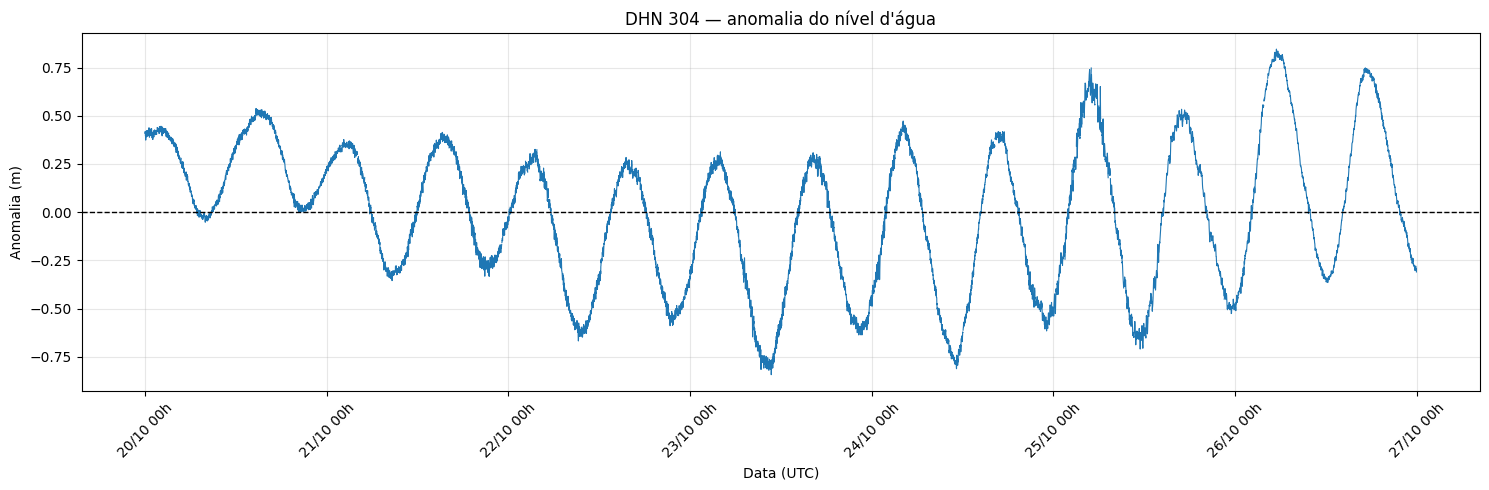

In [10]:
# 9. Anomalia do nível d'água em relação à média do recorte
# A média é calculada somente com observações válidas.
media_nivel_original = nivel_obs.mean()
anomalia_nivel = nivel_obs - media_nivel_original

print(f"Média do nível original: {media_nivel_original:.4f} m")
print(f"Média da anomalia: {anomalia_nivel.mean():.8f} m")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(anomalia_nivel.index, anomalia_nivel, lw=0.8)
ax.axhline(0, color="black", ls="--", lw=1)
ax.set_title("DHN 304 — anomalia do nível d'água")
ax.set_ylabel("Anomalia (m)")
ax.set_xlabel("Data (UTC)")
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh", tz=timezone.utc))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Construiu-se uma tabela comparativa com o número total de amostras ($N$$N$), média e desvio padrão para os três cenários exigidos:
Cenário A: Somente observações válidas (média: $4.079 \text{ m/s}$$4.079 \text{ m/s}$, desvio padrão: $2.300 \text{ m/s}$$2.300 \text{ m/s}$).
Cenário B: Ausentes substituídos por zero (média artificialmente reduzida para $3.496 \text{ m/s}$$3.496 \text{ m/s}$ e desvio aumentado para $2.564 \text{ m/s}$$2.564 \text{ m/s}$).
Cenário C: Interpolação linear de todas as lacunas internas (média: $3.924 \text{ m/s}$$3.924 \text{ m/s}$, desvio padrão: $2.256 \text{ m/s}$$2.256 \text{ m/s}$).

In [11]:
# 10. Três cenários para os ausentes do vento (slide 5)

# Cenário A: somente observações válidas
vento_validos = vento_obs.dropna()

# Cenário B: substituir ausentes por zero (apenas demonstração; não recomendado)
vento_zero = vento_obs.fillna(0)

# Cenário C: interpolar todas as lacunas internas, sem extrapolar as extremidades
vento_interp_todas = vento_obs.interpolate(method="time", limit_area="inside")

def estatisticas_cenario(nome, serie):
    s = serie.dropna()
    return {
        "Tratamento": nome,
        "N": len(s),
        "Média (m/s)": s.mean(),
        "Desvio padrão (m/s)": s.std()
    }

comparacao_vento = pd.DataFrame([
    estatisticas_cenario("Somente valores válidos (adotado)", vento_validos),
    estatisticas_cenario("Ausentes substituídos por zero (incorreto)", vento_zero),
    estatisticas_cenario("Interpolação de todas as lacunas internas", vento_interp_todas)
])
display(comparacao_vento.round(3))

print("Observação: a interpolação de todas as lacunas é somente um cenário comparativo; pode inventar variação durante períodos longos sem medição.")

,Tratamento,N,Média (m/s),Desvio padrão (m/s)
0,Somente valores válidos (adotado),576,4.079,2.300
1,Ausentes substituídos por zero (incorreto),672,3.496,2.564
2,Interpolação de todas as lacunas internas,671,3.924,2.256


Observação: a interpolação de todas as lacunas é somente um cenário comparativo; pode inventar variação durante períodos longos sem medição.


Implementamos uma interpolação temporal restrita pelo parâmetro limit do Pandas:
No nível de água (passo de 1 min), o limite foi configurado em no máximo 5 pontos consecutivos (5 min).
No vento (passo de 30 min), o limite foi de no máximo 3 pontos consecutivos (90 min).
Valores Marcados: Plotamos novos gráficos para ambas as séries exibindo os dados originais em linhas e os pontos interpolados marcados individualmente com marcadores (scatter em destaque), confirmando visualmente que as lacunas longas do vento (maiores que 90 min) continuam preservadas na série temporal sem preenchimento artificial.

DHN: valores interpolados: 90
DHN: ausentes restantes: 0
RJ-4: valores interpolados: 51
RJ-4: ausentes restantes: 45


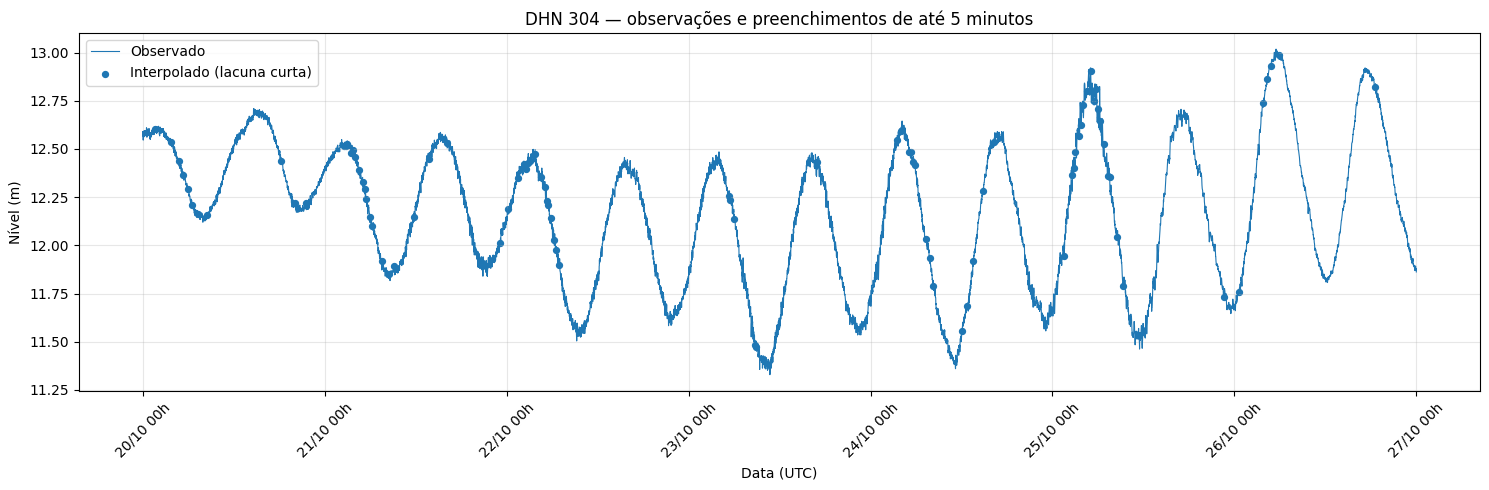

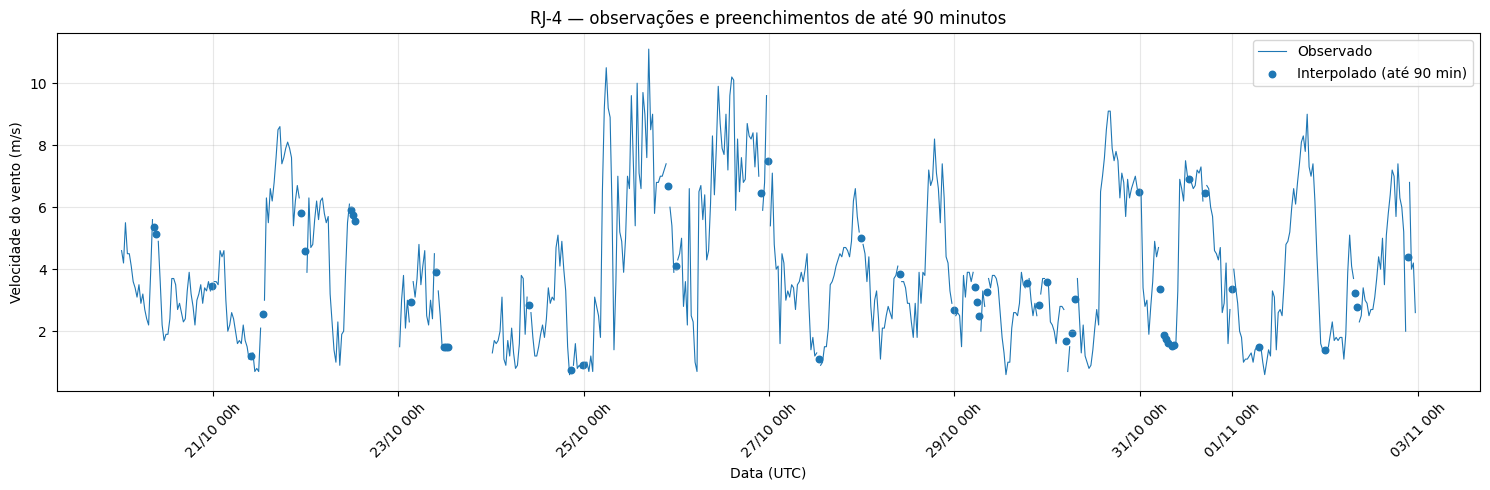

In [12]:
# 11. Interpolação limitada: DHN até 5 min; vento até 90 min
# limit é o número máximo de pontos consecutivos ausentes a preencher.
# Lacunas maiores permanecem NaN. Somente lacunas internas são interpoladas.

nivel_interp = nivel_obs.interpolate(
    method="time", limit=5, limit_area="inside"
)
vento_interp_curto = vento_obs.interpolate(
    method="time", limit=3, limit_area="inside"
)
# No vento, 90 min correspondem a no máximo 3 pontos ausentes consecutivos
# numa grade de 30 min (três pontos = 90 min sem observação).

flag_nivel_preenchido = nivel_obs.isna() & nivel_interp.notna()
flag_vento_preenchido = vento_obs.isna() & vento_interp_curto.notna()

print("DHN: valores interpolados:", int(flag_nivel_preenchido.sum()))
print("DHN: ausentes restantes:", int(nivel_interp.isna().sum()))
print("RJ-4: valores interpolados:", int(flag_vento_preenchido.sum()))
print("RJ-4: ausentes restantes:", int(vento_interp_curto.isna().sum()))

# Gráfico do DHN com os valores interpolados destacados
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(nivel_obs.index, nivel_obs, lw=0.8, label="Observado")
ax.scatter(nivel_interp.index[flag_nivel_preenchido],
           nivel_interp[flag_nivel_preenchido],
           s=18, marker="o", label="Interpolado (lacuna curta)")
ax.set_title("DHN 304 — observações e preenchimentos de até 5 minutos")
ax.set_ylabel("Nível (m)")
ax.set_xlabel("Data (UTC)")
ax.grid(alpha=0.3)
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh", tz=timezone.utc))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico do vento com valores interpolados destacados
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(vento_obs.index, vento_obs, lw=0.8, label="Observado")
ax.scatter(vento_interp_curto.index[flag_vento_preenchido],
           vento_interp_curto[flag_vento_preenchido],
           s=22, marker="o", label="Interpolado (até 90 min)")
ax.set_title("RJ-4 — observações e preenchimentos de até 90 minutos")
ax.set_ylabel("Velocidade do vento (m/s)")
ax.set_xlabel("Data (UTC)")
ax.grid(alpha=0.3)
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh", tz=timezone.utc))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Criou-se uma função de resumo robusta e exportamos o DataFrame contendo exatamente os indicadores requeridos:
1. Número de observações válidas (original).
2. Média amostral e Desvio padrão amostral.
3. Passo amostral real verificado (1 minuto para o marégrafo e 30 minutos para o vento).
4. Maior lacuna sem dados encontrada em cada série (DHN: 1 min | RJ-4: 12 horas e 30 minutos).
5. Menor período fisicamente resolvível pelo limite de Nyquist ($2 \times \text{passo}$$2 \times \text{passo}$). Para o marégrafo, o período mínimo é de 2 minutos; para o vento, é de 1 hora.

In [13]:
# 12. Tabela final de indicadores para o item 1

def estatisticas_finais(nome, serie_original, serie_tratada, passo, lacunas):
    validos = serie_original.dropna()
    return {
        "Série": nome,
        "N válido original": int(validos.count()),
        "Média original": validos.mean(),
        "Desvio padrão original": validos.std(),
        "Passo amostral": str(passo),
        "Nº lacunas": len(lacunas),
        "Maior lacuna sem dado": str(lacunas["duracao_sem_dado"].max()) if len(lacunas) else "0",
        "N interpolado": int((serie_original.isna() & serie_tratada.notna()).sum()),
        "N ausente após interpolação limitada": int(serie_tratada.isna().sum()),
        "Período mínimo Nyquist": str(2*passo)
    }

tabela_final = pd.DataFrame([
    estatisticas_finais("DHN 304 — nível (m)", nivel_obs, nivel_interp,
                        pd.Timedelta(minutes=1), lacunas_dhn),
    estatisticas_finais("RJ-4 — vento (m/s)", vento_obs, vento_interp_curto,
                        pd.Timedelta(minutes=30), lacunas_vento)
])
display(tabela_final)

,Série,N válido original,Média original,Desvio padrão original,Passo amostral,Nº lacunas,Maior lacuna sem dado,N interpolado,N ausente após interpolação limitada,Período mínimo Nyquist
0,DHN 304 — nível (m),9990,12.172060,0.371166,0 days 00:01:00,90,0 days 00:01:00,90,0,0 days 00:02:00
1,RJ-4 — vento (m/s),576,4.078819,2.300012,0 days 00:30:00,41,0 days 12:30:00,51,45,0 days 01:00:00


In [14]:
# 13. Exportar tabelas e séries tratadas para CSV

tabela_resumo.to_csv("item1_resumo_DHN_RJ4.csv", index=False, encoding="utf-8-sig")
comparacao_vento.to_csv("item1_cenarios_vento_RJ4.csv", index=False, encoding="utf-8-sig")
tabela_final.to_csv("item1_tabela_final_DHN_RJ4.csv", index=False, encoding="utf-8-sig")

saida_dhn = pd.DataFrame({
    "nivel_observado_m": nivel_obs,
    "anomalia_m": anomalia_nivel,
    "nivel_interpolado_ate_5min_m": nivel_interp,
    "flag_interpolado": flag_nivel_preenchido
})
saida_dhn.to_csv("DHN304_item1_2026-10-20_a_2026-10-27.csv",
                 index_label="timestamp_UTC", encoding="utf-8-sig")

saida_vento = pd.DataFrame({
    "vento_observado_m_s": vento_obs,
    "vento_interpolado_ate_90min_m_s": vento_interp_curto,
    "flag_interpolado": flag_vento_preenchido
})
saida_vento.to_csv("RJ4_vento_item1_2026-10-20_a_2026-11-03.csv",
                   index_label="timestamp_UTC", encoding="utf-8-sig")

print("CSVs exportados.")

CSVs exportados.


In [15]:
# 2.1 — Preparar séries válidas (SEM interpolação)
# Estas variáveis são criadas nas células do Item 1:
# nivel_obs: nível DHN 304 na grade de 1 min, com NaN nas lacunas
# vento_obs: velocidade do vento RJ-4 na grade de 30 min, com NaN nas lacunas

nivel_ls = nivel_obs.dropna().copy()
vento_ls = vento_obs.dropna().copy()

print("DHN 304 — observações válidas:", len(nivel_ls))
print("RJ-4 — observações válidas:", len(vento_ls))
print("DHN — intervalo:", nivel_ls.index.min(), "a", nivel_ls.index.max())
print("RJ-4 — intervalo:", vento_ls.index.min(), "a", vento_ls.index.max())

# Confirmação: as séries usadas aqui são as originais, não nivel_interp/vento_interp_curto.


DHN 304 — observações válidas: 9990
RJ-4 — observações válidas: 576
DHN — intervalo: 2026-10-20 00:00:00+00:00 a 2026-10-26 23:59:00+00:00
RJ-4 — intervalo: 2026-10-20 00:21:00+00:00 a 2026-11-02 23:21:00+00:00


In [16]:
# 2.2 — Lomb–Scargle para amostragem com lacunas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lombscargle, find_peaks

def calcular_lomb_scargle(serie, nome, periodo_min_h=2.0, fator_resolucao=10):
    """Calcula Lomb–Scargle usando timestamps válidos, sem interpolar.

    Retorna tabela espectral e metadados. A potência é normalizada.
    """
    s = serie.dropna().sort_index()
    if len(s) < 10:
        raise ValueError(f"{nome}: observações insuficientes para Lomb–Scargle.")

    # Tempo decorrido em horas a partir do primeiro timestamp
    t = (s.index - s.index[0]).total_seconds().to_numpy() / 3600.0
    y = s.to_numpy(dtype=float)
    y = y - np.mean(y)  # remove apenas a média; não remove tendência/ciclos

    duracao_h = t[-1] - t[0]
    if duracao_h <= 0:
        raise ValueError(f"{nome}: duração temporal inválida.")

    # Grade de frequências em ciclos por hora.
    # Passo ~ 1/(10*T): dez pontos por largura Rayleigh.
    df = 1.0 / (fator_resolucao * duracao_h)
    f_min = 1.0 / (2.0 * duracao_h)  # permite visualizar a região de baixa frequência
    f_max = 1.0 / periodo_min_h
    frequencias = np.arange(f_min, f_max, df)

    potencia = lombscargle(
        t, y, 2 * np.pi * frequencias,
        floating_mean=True,
        normalize=True
    )

    espectro = pd.DataFrame({
        "frequencia_cph": frequencias,
        "periodo_h": 1.0 / frequencias,
        "potencia": potencia
    }).sort_values("frequencia_cph").reset_index(drop=True)

    return espectro, {
        "nome": nome,
        "n_validos": len(s),
        "duracao_h": duracao_h,
        "duracao_dias": duracao_h / 24,
        "periodo_5_ciclos_h": duracao_h / 5,
        "delta_f_rayleigh_cph": 1.0 / duracao_h
    }

espectro_nivel, info_nivel = calcular_lomb_scargle(
    nivel_ls, "Nível DHN 304", periodo_min_h=2
)
espectro_vento, info_vento = calcular_lomb_scargle(
    vento_ls, "Vento RJ-4", periodo_min_h=2
)

display(pd.DataFrame([info_nivel, info_vento]).set_index("nome").round(4))


,n_validos,duracao_h,duracao_dias,periodo_5_ciclos_h,delta_f_rayleigh_cph
nome,,,,,
Nível DHN 304,9990,167.9833,6.9993,33.5967,0.006
Vento RJ-4,576,335.0000,13.9583,67.0000,0.003


In [17]:
# 2.3 — Identificar picos candidatos no periodograma
def listar_picos(espectro, nome, n_picos=12):
    p = espectro["potencia"].to_numpy()
    indices, _ = find_peaks(p, distance=3)

    # Incluir também o máximo global, caso esteja na borda da grade
    if len(indices) == 0:
        indices = np.array([int(np.argmax(p))])
    else:
        indices = np.unique(np.append(indices, int(np.argmax(p))))

    idx = sorted(indices, key=lambda i: p[i], reverse=True)[:n_picos]
    tabela = espectro.iloc[idx][["periodo_h", "frequencia_cph", "potencia"]].copy()
    tabela.insert(0, "Série", nome)
    tabela["período_dias"] = tabela["periodo_h"] / 24
    return tabela.sort_values("potencia", ascending=False).reset_index(drop=True)

picos_nivel = listar_picos(espectro_nivel, "DHN 304 — nível")
picos_vento = listar_picos(espectro_vento, "RJ-4 — vento")

print("Picos candidatos — DHN 304")
display(picos_nivel.round(4))
print("Picos candidatos — RJ-4")
display(picos_vento.round(4))


Picos candidatos — DHN 304


,Série,periodo_h,frequencia_cph,potencia,período_dias
0,DHN 304 — nível,12.2616,0.0816,0.7229,0.5109
1,DHN 304 — nível,209.9792,0.0048,0.1952,8.7491
2,DHN 304 — nível,69.9931,0.0143,0.0295,2.9164
3,DHN 304 — nível,13.6572,0.0732,0.0267,0.5690
4,DHN 304 — nível,11.1247,0.0899,0.0214,0.4635
5,DHN 304 — nível,47.9952,0.0208,0.0184,1.9998
6,DHN 304 — nível,28.4718,0.0351,0.0175,1.1863
7,DHN 304 — nível,36.5181,0.0274,0.0145,1.5216
8,DHN 304 — nível,14.8658,0.0673,0.0108,0.6194
9,DHN 304 — nível,10.4337,0.0958,0.0079,0.4347


Picos candidatos — RJ-4


,Série,periodo_h,frequencia_cph,potencia,período_dias
0,RJ-4 — vento,23.9286,0.0418,0.1997,0.9970
1,RJ-4 — vento,104.6875,0.0096,0.1282,4.3620
2,RJ-4 — vento,29.1304,0.0343,0.0933,1.2138
3,RJ-4 — vento,21.6129,0.0463,0.0782,0.9005
4,RJ-4 — vento,55.8333,0.0179,0.0622,2.3264
5,RJ-4 — vento,71.2766,0.0140,0.0498,2.9699
6,RJ-4 — vento,43.5065,0.0230,0.0478,1.8128
7,RJ-4 — vento,16.5842,0.0603,0.0381,0.6910
8,RJ-4 — vento,10.7372,0.0931,0.0348,0.4474
9,RJ-4 — vento,12.0504,0.0830,0.0325,0.5021


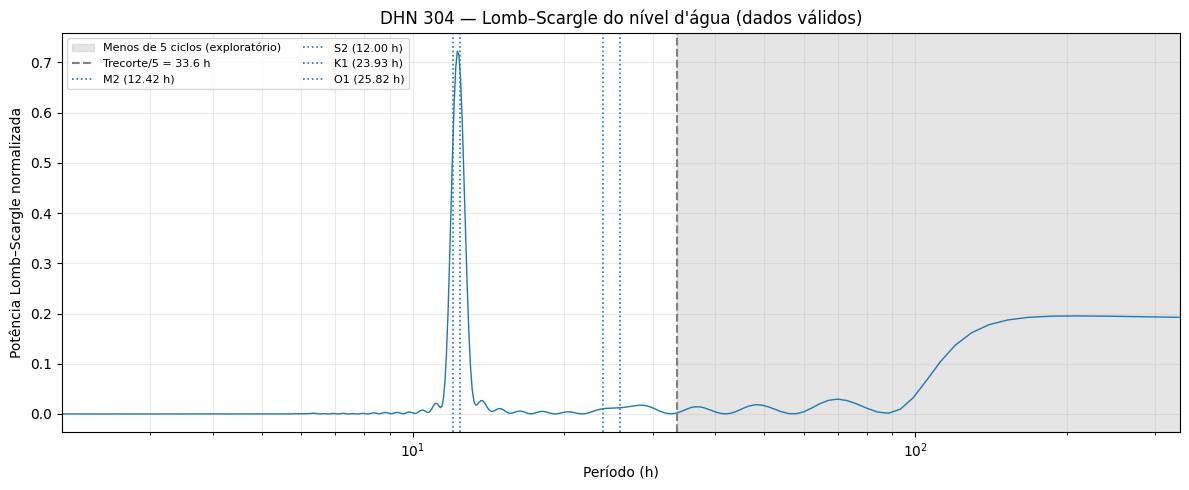

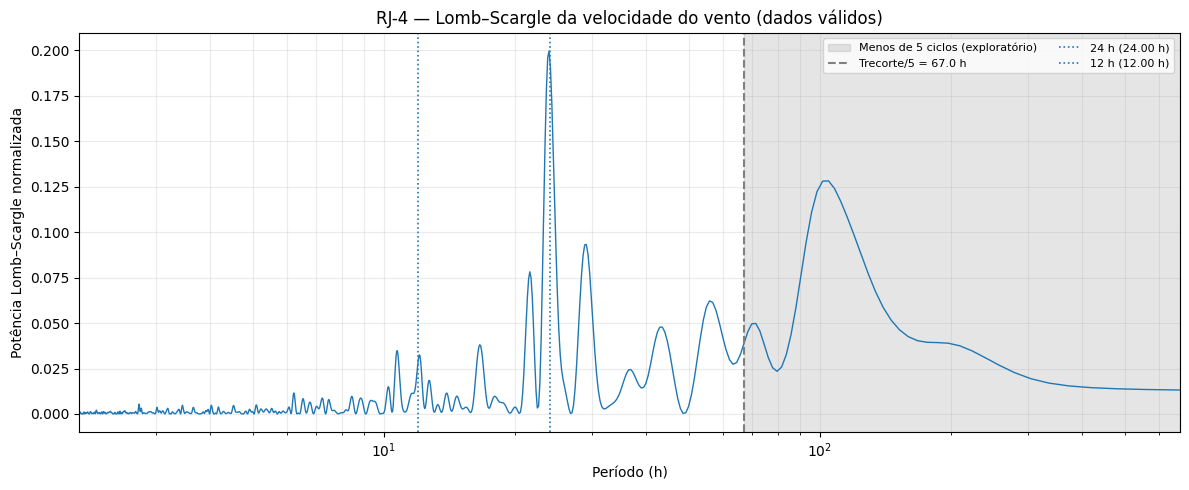

In [18]:
# 2.4 — Gráficos dos periodogramas e referências físicas
# A região sombreada corresponde a períodos com menos de ~5 ciclos no recorte.
def plotar_periodograma(espectro, info, titulo, periodos_referencia):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(espectro["periodo_h"], espectro["potencia"], lw=1)
    ax.set_xscale("log")
    ax.set_xlim(espectro["periodo_h"].min(), espectro["periodo_h"].max())
    ax.set_xlabel("Período (h)")
    ax.set_ylabel("Potência Lomb–Scargle normalizada")
    ax.set_title(titulo)
    ax.grid(True, which="both", alpha=0.25)

    corte_5 = info["periodo_5_ciclos_h"]
    ax.axvspan(corte_5, espectro["periodo_h"].max(),
               color="gray", alpha=0.20,
               label="Menos de 5 ciclos (exploratório)")
    ax.axvline(corte_5, color="gray", ls="--",
               label=f"Trecorte/5 = {corte_5:.1f} h")

    for periodo, rotulo in periodos_referencia:
        ax.axvline(periodo, ls=":", lw=1.2, label=f"{rotulo} ({periodo:.2f} h)")

    ax.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()

plotar_periodograma(
    espectro_nivel, info_nivel,
    "DHN 304 — Lomb–Scargle do nível d'água (dados válidos)",
    [(12.4206, "M2"), (12.0, "S2"), (23.9345, "K1"), (25.8193, "O1")]
)

plotar_periodograma(
    espectro_vento, info_vento,
    "RJ-4 — Lomb–Scargle da velocidade do vento (dados válidos)",
    [(24.0, "24 h"), (12.0, "12 h")]
)


In [19]:
# 2.5 — Critério de Rayleigh e regra prática de cinco ciclos
# Duração mínima de Rayleigh = 1 / |f1 - f2|, com f em ciclos por hora.
def duracao_rayleigh_h(periodo1_h, periodo2_h):
    f1 = 1.0 / periodo1_h
    f2 = 1.0 / periodo2_h
    return 1.0 / abs(f1 - f2)

pares_ciclos = [
    ("Nível: M2 × S2", 12.4206, 12.0000, info_nivel),
    ("Nível: K1 × O1", 23.9345, 25.8193, info_nivel),
    ("Nível: M2 × K1", 12.4206, 23.9345, info_nivel),
    ("Vento: 24 h × 12 h", 24.0000, 12.0000, info_vento)
]

linhas = []
for nome, p1, p2, info in pares_ciclos:
    t_rayleigh = duracao_rayleigh_h(p1, p2)
    t_recorte = info["duracao_h"]
    linhas.append({
        "Par de ciclos": nome,
        "Períodos (h)": f"{p1:.2f} × {p2:.2f}",
        "Rayleigh necessário (dias)": t_rayleigh / 24,
        "Recorte (dias)": t_recorte / 24,
        "Rayleigh atendido": t_recorte > t_rayleigh,
        "5 ciclos do mais lento (dias)": (5 * max(p1, p2)) / 24,
        "5 ciclos atendidos": t_recorte >= 5 * max(p1, p2)
    })

tabela_rayleigh = pd.DataFrame(linhas)
display(tabela_rayleigh.round(2))


,Par de ciclos,Períodos (h),Rayleigh necessário (dias),Recorte (dias),Rayleigh atendido,5 ciclos do mais lento (dias),5 ciclos atendidos
0,Nível: M2 × S2,12.42 × 12.00,14.77,7.00,False,2.59,True
1,Nível: K1 × O1,23.93 × 25.82,13.66,7.00,False,5.38,True
2,Nível: M2 × K1,12.42 × 23.93,1.08,7.00,True,4.99,True
3,Vento: 24 h × 12 h,24.00 × 12.00,1.00,13.96,True,5.00,True


In [20]:
# 2.7 — Exportar resultados do item 2
picos_nivel.to_csv("item2_picos_LombScargle_DHN304.csv", index=False, encoding="utf-8-sig")
picos_vento.to_csv("item2_picos_LombScargle_RJ4_vento.csv", index=False, encoding="utf-8-sig")
tabela_rayleigh.to_csv("item2_criterio_Rayleigh.csv", index=False, encoding="utf-8-sig")

espectro_nivel.to_csv("item2_espectro_LombScargle_DHN304.csv", index=False, encoding="utf-8-sig")
espectro_vento.to_csv("item2_espectro_LombScargle_RJ4_vento.csv", index=False, encoding="utf-8-sig")

print("Arquivos CSV do item 2 exportados.")


Arquivos CSV do item 2 exportados.


In [21]:
# 3.1 — Ajuste conjunto: reta + harmônicos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PERIODOS_NIVEL_H = {"M2": 12.4206, "K1": 23.9345}
PERIODOS_VENTO_H = {"24 h": 24.0, "12 h": 12.0}

def ajustar_tendencia_harmonicos(serie, nome, periodos_h):
    """OLS conjunto de intercepto + tendência linear + seno/cosseno.

    A série deve ter DatetimeIndex e valores numéricos. Não interpola ausentes.
    """
    s = serie.dropna().sort_index().astype(float)
    if not isinstance(s.index, pd.DatetimeIndex):
        raise TypeError(f"{nome}: o índice precisa ser DatetimeIndex.")
    if len(s) < 20:
        raise ValueError(f"{nome}: poucas observações válidas para o ajuste.")

    t0 = s.index.min()
    t_dias = (s.index - t0).total_seconds().to_numpy() / 86400.0
    y = s.to_numpy()
    t_centro = t_dias - np.mean(t_dias)

    colunas = [np.ones(len(s)), t_centro]
    nomes_colunas = ["intercepto", "tendencia_por_dia"]
    for rotulo, periodo_h in periodos_h.items():
        fase = 2.0 * np.pi * (t_dias * 24.0) / float(periodo_h)
        colunas.extend([np.sin(fase), np.cos(fase)])
        nomes_colunas.extend([f"sin_{rotulo}", f"cos_{rotulo}"])

    X = np.column_stack(colunas)
    beta, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
    if rank < X.shape[1]:
        raise ValueError(f"{nome}: matriz do modelo não tem posto completo.")

    ajustado = X @ beta
    ciclo = np.zeros_like(y, dtype=float)
    for j, rotulo in enumerate(periodos_h):
        b_sin = beta[2 + 2*j]
        b_cos = beta[3 + 2*j]
        fase = 2.0 * np.pi * (t_dias * 24.0) / float(periodos_h[rotulo])
        ciclo += b_sin * np.sin(fase) + b_cos * np.cos(fase)

    tendencia = beta[1] * t_centro
    dessazonalizada = y - ciclo
    residuo = y - ajustado

    resultado = pd.DataFrame({
        "original": y,
        "tendencia_ajustada": beta[0] + tendencia,
        "ciclo_ajustado": ciclo,
        "dessazonalizada": dessazonalizada,
        "residuo": residuo,
        "ajuste_completo": ajustado
    }, index=s.index)

    return {
        "nome": nome, "serie": s, "resultado": resultado,
        "beta": pd.Series(beta, index=nomes_colunas),
        "X": X, "y": y, "residuo_array": residuo,
        "t_dias": t_dias, "periodos_h": periodos_h,
        "n": len(s), "graus_liberdade": len(s)-X.shape[1],
        "t0": t0
    }

ajuste_nivel = ajustar_tendencia_harmonicos(
    nivel_obs, "DHN 304 — nível", PERIODOS_NIVEL_H
)
ajuste_vento = ajustar_tendencia_harmonicos(
    vento_obs, "RJ-4 — velocidade do vento", PERIODOS_VENTO_H
)

print("Coeficientes do ajuste — DHN 304")
display(ajuste_nivel["beta"].to_frame("coeficiente").round(6))
print("Coeficientes do ajuste — RJ-4")
display(ajuste_vento["beta"].to_frame("coeficiente").round(6))

Coeficientes do ajuste — DHN 304


,coeficiente
intercepto,12.167653
tendencia_por_dia,-0.011329
sin_M2,0.247656
cos_M2,0.353439
sin_K1,-0.013654
cos_K1,0.034818


Coeficientes do ajuste — RJ-4


,coeficiente
intercepto,4.118677
tendencia_por_dia,-0.013908
sin_24 h,-1.439482
cos_24 h,-0.129981
sin_12 h,0.019707
cos_12 h,-0.561225


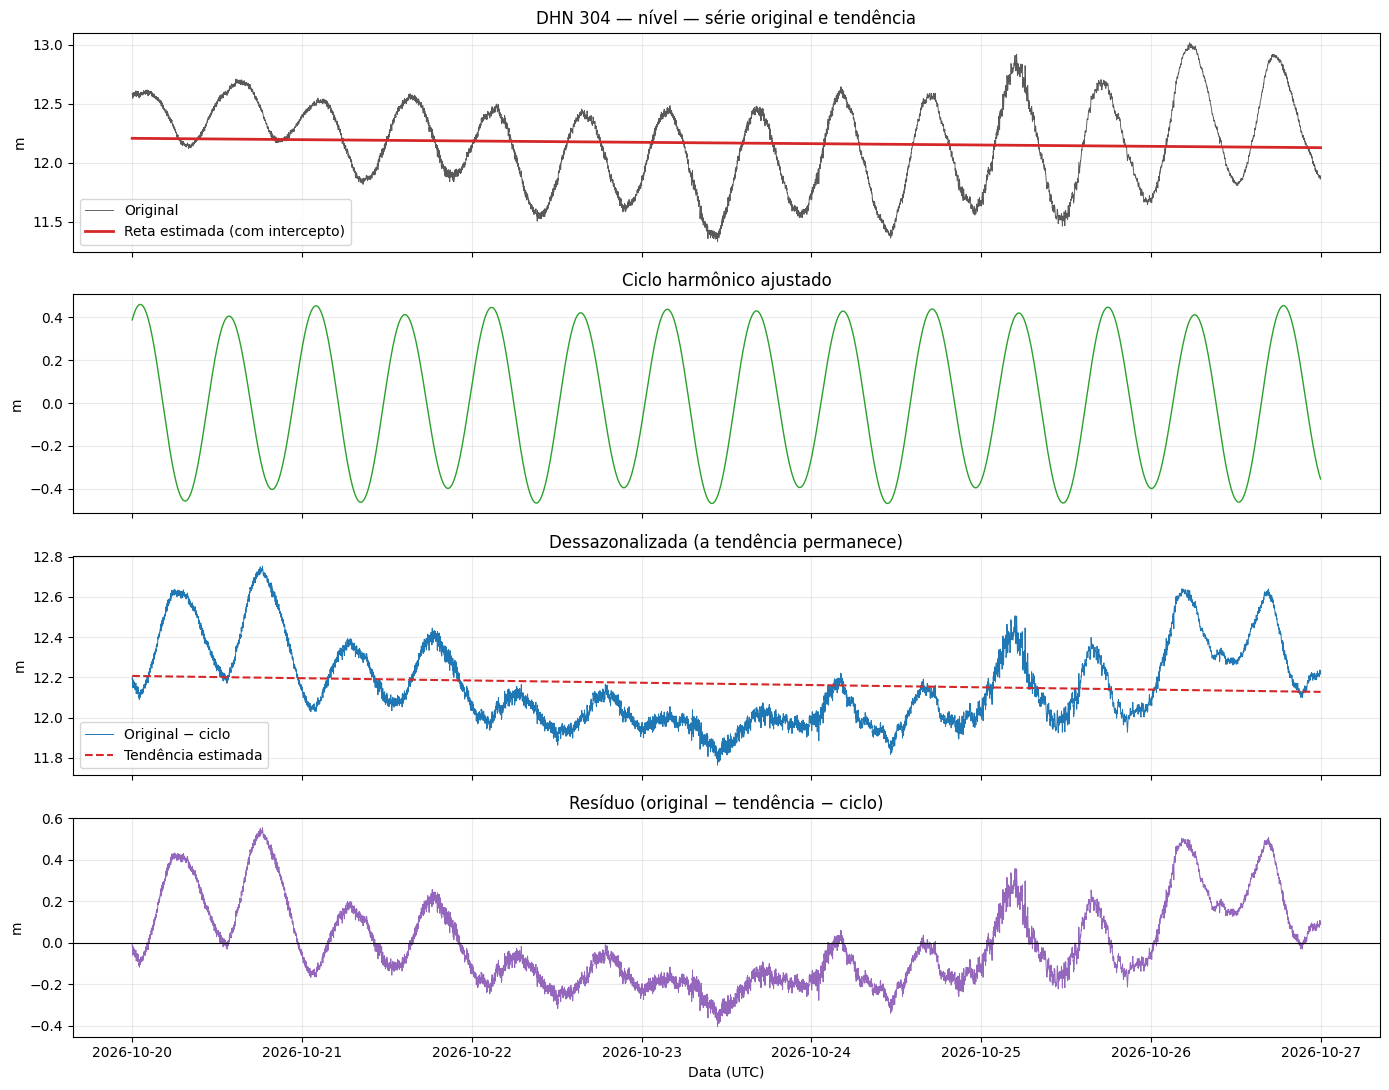

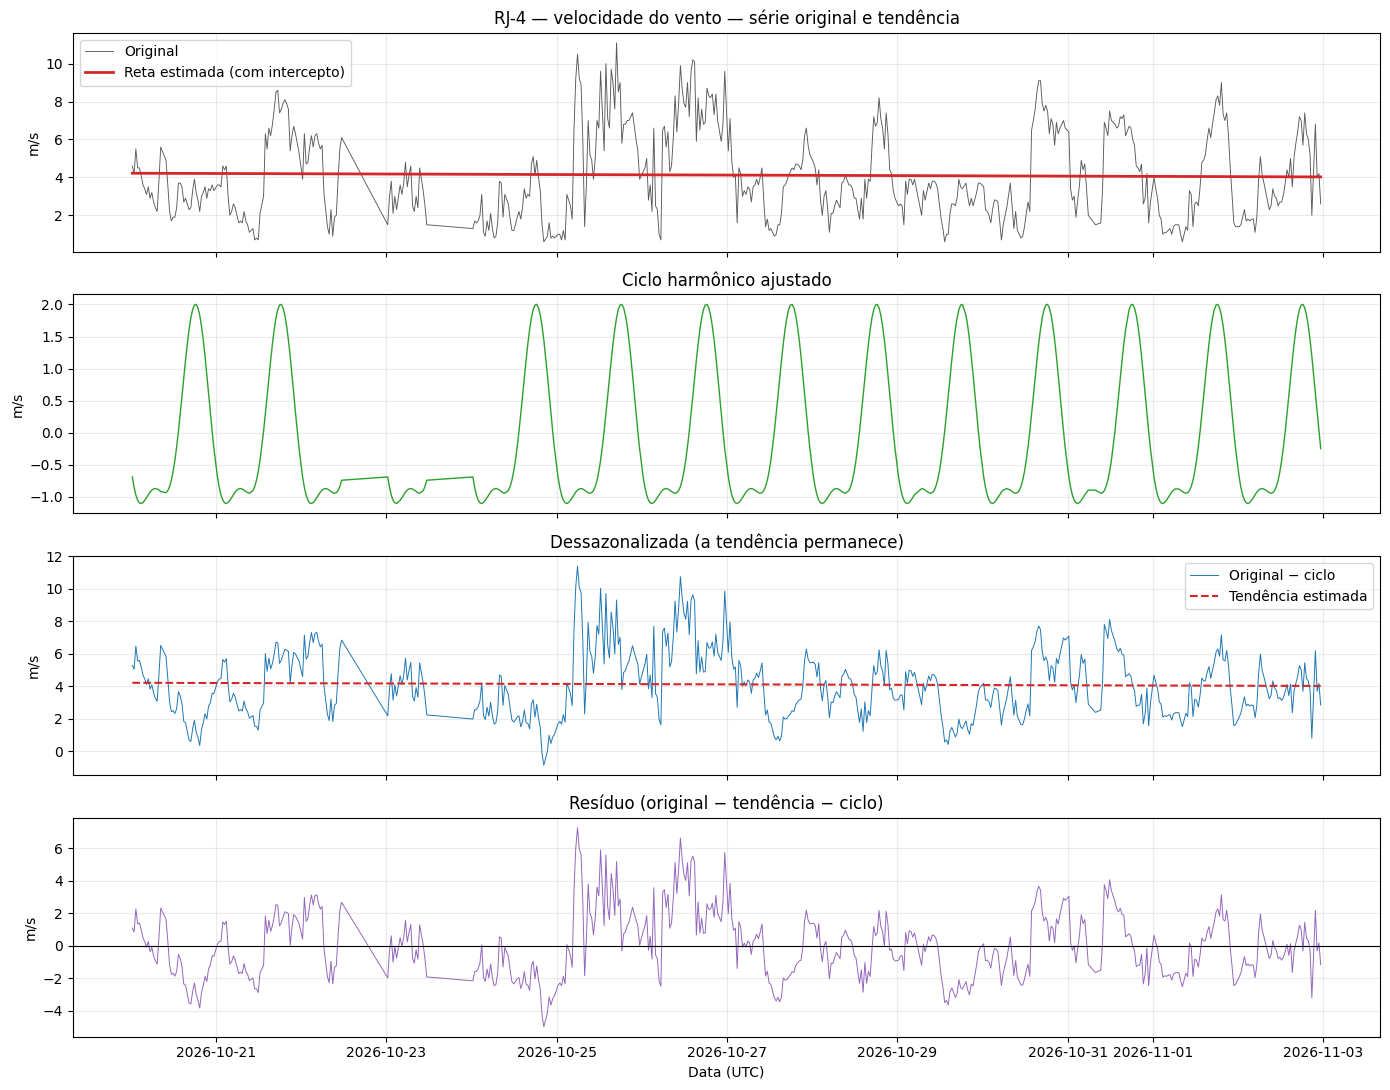

In [22]:
# 3.2 — Gráficos: original + reta, ciclo, dessazonalizada e resíduo
def plotar_decomposicao(ajuste, unidade):
    d = ajuste["resultado"]
    fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

    axes[0].plot(d.index, d["original"], color="0.35", lw=0.65, label="Original")
    axes[0].plot(d.index, d["tendencia_ajustada"], color="tab:red", lw=2,
                 label="Reta estimada (com intercepto)")
    axes[0].set_title(f"{ajuste['nome']} — série original e tendência")
    axes[0].set_ylabel(unidade); axes[0].legend(); axes[0].grid(alpha=.25)

    axes[1].plot(d.index, d["ciclo_ajustado"], color="tab:green", lw=1)
    axes[1].set_title("Ciclo harmônico ajustado"); axes[1].set_ylabel(unidade); axes[1].grid(alpha=.25)

    axes[2].plot(d.index, d["dessazonalizada"], color="tab:blue", lw=.7,
                 label="Original − ciclo")
    axes[2].plot(d.index, d["tendencia_ajustada"], color="tab:red", ls="--", lw=1.5,
                 label="Tendência estimada")
    axes[2].set_title("Dessazonalizada (a tendência permanece)")
    axes[2].set_ylabel(unidade); axes[2].legend(); axes[2].grid(alpha=.25)

    axes[3].plot(d.index, d["residuo"], color="tab:purple", lw=.7)
    axes[3].axhline(0, color="black", lw=.8)
    axes[3].set_title("Resíduo (original − tendência − ciclo)")
    axes[3].set_ylabel(unidade); axes[3].set_xlabel("Data (UTC)"); axes[3].grid(alpha=.25)

    fig.tight_layout(); plt.show()

plotar_decomposicao(ajuste_nivel, "m")
plotar_decomposicao(ajuste_vento, "m/s")

In [23]:
# 3.3 — Desvios padrão: original, dessazonalizada e resíduo
linhas_dp = []
for ajuste, unidade in [(ajuste_nivel, "m"), (ajuste_vento, "m/s")]:
    d = ajuste["resultado"]
    for etapa, coluna in [
        ("Original", "original"),
        ("Dessazonalizada (ciclo removido)", "dessazonalizada"),
        ("Resíduo (ciclo + tendência removidos)", "residuo")
    ]:
        linhas_dp.append({
            "Série": ajuste["nome"], "Etapa": etapa,
            "N": d[coluna].count(), "Desvio padrão": d[coluna].std(ddof=1),
            "Unidade": unidade
        })

tabela_dp_item3 = pd.DataFrame(linhas_dp)
print("Comparação dos desvios padrão")
display(tabela_dp_item3.pivot(index="Etapa", columns="Série", values="Desvio padrão").round(4))

Comparação dos desvios padrão


Série,DHN 304 — nível,RJ-4 — velocidade do vento
Etapa,,
Dessazonalizada (ciclo removido),0.2077,2.0225
Original,0.3712,2.3000
Resíduo (ciclo + tendência removidos),0.2064,2.0217


In [24]:
# Dependência para erro-padrão robusto à autocorrelação (Newey–West)
%pip -q install statsmodels

In [25]:
# 3.4 — Incerteza da inclinação com correção HAC/Newey–West
# HAC usa a ordem temporal das observações válidas. A banda de defasagens
# automática segue uma regra conservadora baseada no tamanho amostral.

def n_efetivo_acf(residuos, max_lag=None):
    """Estimativa diagnóstica de n efetivo pela soma de autocorrelações positivas."""
    x = np.asarray(residuos, dtype=float)
    x = x - np.mean(x)
    n = len(x)
    if max_lag is None:
        max_lag = min(n // 4, 5000)
    denom = np.dot(x, x)
    if denom <= 0:
        return float(n), 0
    soma = 0.0
    lag_usado = 0
    for lag in range(1, max_lag + 1):
        rho = np.dot(x[:-lag], x[lag:]) / denom
        if rho <= 0:
            break
        soma += rho
        lag_usado = lag
    n_eff = n / (1.0 + 2.0 * soma)
    return max(1.0, min(float(n), n_eff)), lag_usado


def incerteza_inclinacao_hac(ajuste):
    try:
        import statsmodels.api as sm
        from statsmodels.stats.sandwich_covariance import cov_hac
    except ImportError as exc:
        raise ImportError(
            "Instale statsmodels com: %pip install statsmodels e execute novamente esta célula."
        ) from exc

    X = ajuste["X"]
    y = ajuste["y"]
    modelo = sm.OLS(y, X).fit()
    # Regra automática Newey–West; evita assumir independência dos resíduos.
    nlags = max(1, int(np.floor(4 * (len(y) / 100.0) ** (2.0 / 9.0))))
    cov = cov_hac(modelo, nlags=nlags)
    se_hac = float(np.sqrt(max(cov[1, 1], 0.0)))
    inclinacao = float(modelo.params[1])

    n_eff, lag_positivo = n_efetivo_acf(modelo.resid)
    gl = max(1, int(round(n_eff)) - X.shape[1])
    tcrit = stats.t.ppf(0.975, gl)
    # IC principal usa erro-padrão HAC e referência t com graus de liberdade efetivos.
    ic_inf = inclinacao - tcrit * se_hac
    ic_sup = inclinacao + tcrit * se_hac

    return {
        "Série": ajuste["nome"], "Inclinação por dia": inclinacao,
        "Erro-padrão HAC": se_hac, "IC95% inferior": ic_inf,
        "IC95% superior": ic_sup, "Inclui zero": ic_inf <= 0 <= ic_sup,
        "N válido": len(y), "N efetivo (ACF positiva)": n_eff,
        "Defasagens HAC": nlags, "Última defasagem ACF positiva": lag_positivo
    }

resumo_tendencias = pd.DataFrame([
    incerteza_inclinacao_hac(ajuste_nivel),
    incerteza_inclinacao_hac(ajuste_vento)
])
print("Inclinação e intervalo de confiança de 95% com correção HAC")
display(resumo_tendencias.round(5))

Inclinação e intervalo de confiança de 95% com correção HAC


,Série,Inclinação por dia,Erro-padrão HAC,IC95% inferior,IC95% superior,Inclui zero,N válido,N efetivo (ACF positiva),Defasagens HAC,Última defasagem ACF positiva
0,DHN 304 — nível,-0.01133,0.00419,-0.02935,0.00669,True,9990,7.73435,11,1749
1,RJ-4 — velocidade do vento,-0.01391,0.03860,-0.09286,0.06504,True,576,34.67185,5,30


In [26]:
# 3.6 — Exportar séries decompostas, desvios padrão e tendência/IC
ajuste_nivel["resultado"].to_csv("item3_decomposicao_DHN304.csv", encoding="utf-8-sig")
ajuste_vento["resultado"].to_csv("item3_decomposicao_RJ4_vento.csv", encoding="utf-8-sig")
tabela_dp_item3.to_csv("item3_desvios_padrao.csv", index=False, encoding="utf-8-sig")
resumo_tendencias.to_csv("item3_tendencia_IC_HAC.csv", index=False, encoding="utf-8-sig")
print("Arquivos CSV do item 3 exportados com sucesso.")

Arquivos CSV do item 3 exportados com sucesso.


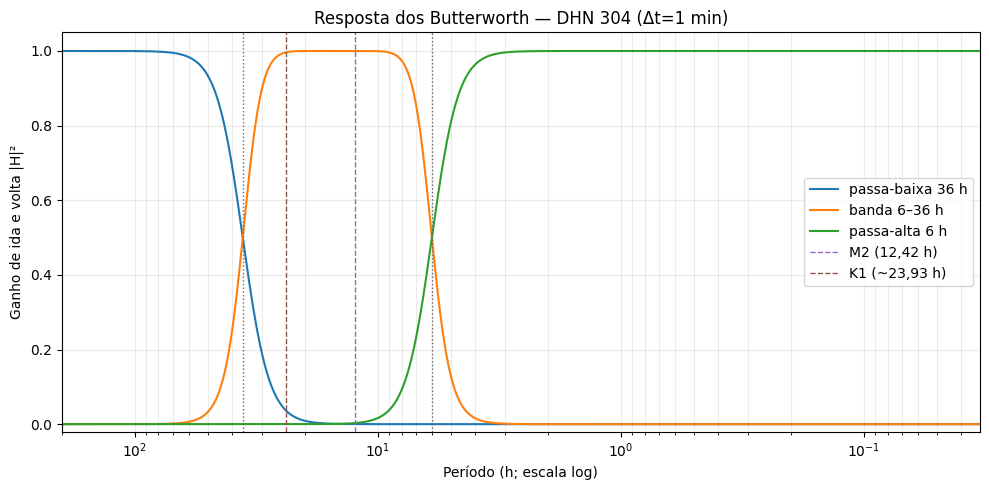

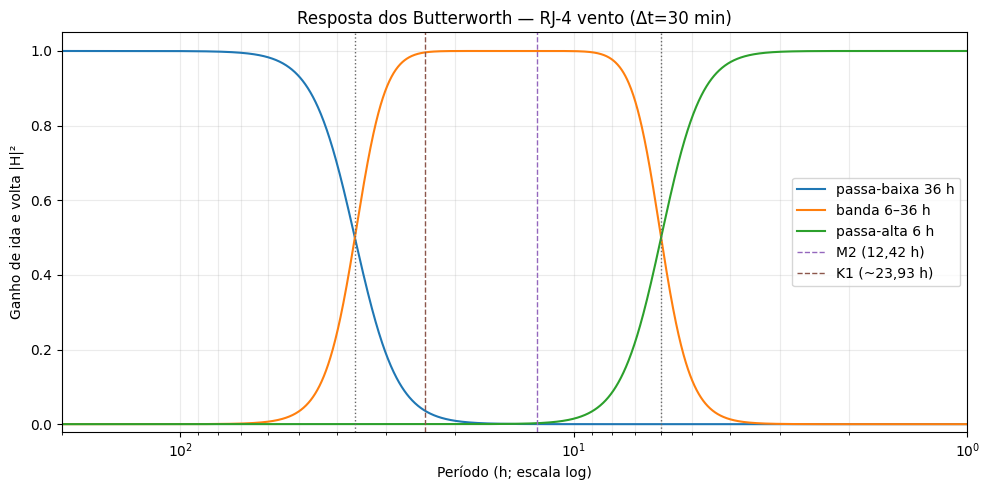

M2 (12,42 h) e K1 (~23,93 h) situam-se na banda de 6–36 h.
A resposta de 1 min e 30 min deve coincidir nas frequências comuns, salvo diferenças numéricas de discretização.


In [27]:
# 4.1 — Definição dos filtros Butterworth (ordem 4) e resposta em função do período
from scipy.signal import butter, sosfiltfilt, sosfreqz

ORDEM_BUTTER = 4
CORTES_PERIODO_H = {"passa-baixa 36 h": 36.0, "passa-alta 6 h": 6.0}

def criar_filtros_butterworth(passo_minutos, ordem=4):
    """Cria SOS com frequência de amostragem expressa em amostras por hora."""
    dt_h = passo_minutos / 60.0
    fs_h = 1.0 / dt_h
    nyquist_h = fs_h / 2.0
    f36 = 1.0 / 36.0  # ciclos por hora
    f6 = 1.0 / 6.0    # ciclos por hora
    if f6 >= nyquist_h:
        raise ValueError(f"Corte de 6 h acima/igual a Nyquist para passo {passo_minutos} min.")
    return {
        "passa-baixa 36 h": butter(ordem, f36, btype="lowpass", fs=fs_h, output="sos"),
        "banda 6–36 h": butter(ordem, [f36, f6], btype="bandpass", fs=fs_h, output="sos"),
        "passa-alta 6 h": butter(ordem, f6, btype="highpass", fs=fs_h, output="sos"),
    }

# Resposta em frequência (ida e volta): |H|². Frequência em ciclos/hora; eixo convertido para período.
def plotar_resposta_butterworth(passo_minutos, titulo):
    dt_h = passo_minutos / 60.0
    fs_h = 1.0 / dt_h
    filtros = criar_filtros_butterworth(passo_minutos, ORDEM_BUTTER)
    f = np.geomspace(1.0 / 200.0, fs_h / 2.0, 2500)
    periodos = 1.0 / f
    fig, ax = plt.subplots(figsize=(10, 5))
    for nome, sos in filtros.items():
        _, h = sosfreqz(sos, worN=f, fs=fs_h)
        ganho_ida_volta = np.abs(h) ** 2
        ax.semilogx(periodos, ganho_ida_volta, label=nome)
    ax.axvline(36, color="0.4", ls=":", lw=1)
    ax.axvline(6, color="0.4", ls=":", lw=1)
    ax.axvline(12.4206, color="tab:purple", ls="--", lw=1, label="M2 (12,42 h)")
    ax.axvline(23.9345, color="tab:brown", ls="--", lw=1, label="K1 (~23,93 h)")
    ax.set_xlim(200, 2.0*dt_h)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel("Período (h; escala log)")
    ax.set_ylabel("Ganho de ida e volta |H|²")
    ax.set_title(f"Resposta dos Butterworth — {titulo} (Δt={passo_minutos} min)")
    ax.grid(True, which="both", alpha=.25); ax.legend()
    plt.tight_layout(); plt.show()

plotar_resposta_butterworth(1, "DHN 304")
plotar_resposta_butterworth(30, "RJ-4 vento")

print("M2 (12,42 h) e K1 (~23,93 h) situam-se na banda de 6–36 h.")
print("A resposta de 1 min e 30 min deve coincidir nas frequências comuns, salvo diferenças numéricas de discretização.")

In [28]:
# 4.2 — Filtrar somente trechos regulares; identificar bordas e trechos curtos
def filtrar_trechos_regulares(serie, passo_minutos, nome_serie):
    """
    Aplica sosfiltfilt em cada trecho de amostras válidas consecutivas.
    Não preenche lacunas. A borda é marcada por um período de corte: 36 h
    para passa-baixa/banda e 6 h para passa-alta. Trechos sem interior confiável
    após a remoção das bordas ficam integralmente sem saída.
    """
    s = serie.copy().astype(float).sort_index()
    if not isinstance(s.index, pd.DatetimeIndex):
        raise TypeError("A série precisa ter DatetimeIndex.")
    dt = pd.Timedelta(minutes=passo_minutos)
    filtros = criar_filtros_butterworth(passo_minutos, ORDEM_BUTTER)
    nomes = list(filtros)
    saida = pd.DataFrame(index=s.index)
    for nome in nomes:
        saida[nome] = np.nan
        saida[f"{nome} — borda"] = False
        saida[f"{nome} — trecho_curto"] = False

    # Segmentação: só une amostras válidas cuja diferença temporal seja exatamente o passo.
    valido = s.notna().to_numpy()
    pos = np.flatnonzero(valido)
    segmentos = []
    if len(pos):
        inicio = anterior = pos[0]
        for atual in pos[1:]:
            dt_real = s.index[atual] - s.index[anterior]
            if atual != anterior + 1 or dt_real != dt:
                segmentos.append((inicio, anterior + 1))
                inicio = atual
            anterior = atual
        segmentos.append((inicio, anterior + 1))

    registros_segmentos = []
    for i0, i1 in segmentos:
        idx = s.index[i0:i1]
        y = s.iloc[i0:i1].to_numpy(dtype=float)
        n = len(y)
        for nome, sos in filtros.items():
            # SOS filtfilt exige comprimento superior ao padlen padrão.
            zeros_at_origin = int((sos[:, 2] == 0).sum())
            poles_at_origin = int((sos[:, 5] == 0).sum())
            padlen = 3 * (2 * len(sos) + 1 - min(zeros_at_origin, poles_at_origin))
            # Margem conservadora de borda: um período do corte mais lento relevante.
            guarda_h = 36.0 if nome in ("passa-baixa 36 h", "banda 6–36 h") else 6.0
            guarda = int(np.ceil(guarda_h * 60.0 / passo_minutos))
            minimo = max(padlen + 1, 2 * guarda + 3)
            if n < minimo:
                saida.loc[idx, f"{nome} — trecho_curto"] = True
                continue
            try:
                yf = sosfiltfilt(sos, y)
            except ValueError:
                saida.loc[idx, f"{nome} — trecho_curto"] = True
                continue
            saida.loc[idx, nome] = yf
            borda = np.zeros(n, dtype=bool)
            borda[:guarda] = True
            borda[-guarda:] = True
            saida.loc[idx, f"{nome} — borda"] = borda
            # Registra somente o interior como comparável; nas bordas o valor fica disponível,
            # mas explicitamente marcado como menos confiável.
        registros_segmentos.append({"início": idx[0], "fim": idx[-1], "N": n})

    return saida, pd.DataFrame(registros_segmentos)

# Entrada: séries observadas originais, sem as séries interpoladas do item 1.
resultado_filtros_dhn, segmentos_dhn = filtrar_trechos_regulares(nivel_obs, 1, "DHN 304")
resultado_filtros_vento, segmentos_vento = filtrar_trechos_regulares(vento_obs, 30, "RJ-4 vento")

print("Segmentos regulares DHN 304:")
display(segmentos_dhn)
print("Segmentos regulares RJ-4:")
display(segmentos_vento)

Segmentos regulares DHN 304:


,início,fim,N
0,2026-10-20 00:00:00+00:00,2026-10-20 01:36:00+00:00,97
1,2026-10-20 01:38:00+00:00,2026-10-20 03:45:00+00:00,128
2,2026-10-20 03:47:00+00:00,2026-10-20 04:46:00+00:00,60
3,2026-10-20 04:48:00+00:00,2026-10-20 05:17:00+00:00,30
4,2026-10-20 05:19:00+00:00,2026-10-20 06:00:00+00:00,42
...,...,...,...
86,2026-10-26 03:50:00+00:00,2026-10-26 04:18:00+00:00,29
87,2026-10-26 04:20:00+00:00,2026-10-26 04:47:00+00:00,28
88,2026-10-26 04:49:00+00:00,2026-10-26 05:48:00+00:00,60
89,2026-10-26 05:50:00+00:00,2026-10-26 18:32:00+00:00,763


Segmentos regulares RJ-4:


,início,fim,N
0,2026-10-20 00:21:00+00:00,2026-10-20 08:21:00+00:00,17
1,2026-10-20 09:51:00+00:00,2026-10-20 23:21:00+00:00,28
2,2026-10-21 00:21:00+00:00,2026-10-21 09:21:00+00:00,19
3,2026-10-21 10:21:00+00:00,2026-10-21 12:21:00+00:00,5
4,2026-10-21 13:21:00+00:00,2026-10-21 22:21:00+00:00,19
5,2026-10-21 23:21:00+00:00,2026-10-21 23:21:00+00:00,1
6,2026-10-22 00:21:00+00:00,2026-10-22 11:21:00+00:00,23
7,2026-10-23 00:21:00+00:00,2026-10-23 02:51:00+00:00,6
8,2026-10-23 03:51:00+00:00,2026-10-23 09:21:00+00:00,12
9,2026-10-23 10:21:00+00:00,2026-10-23 11:21:00+00:00,3


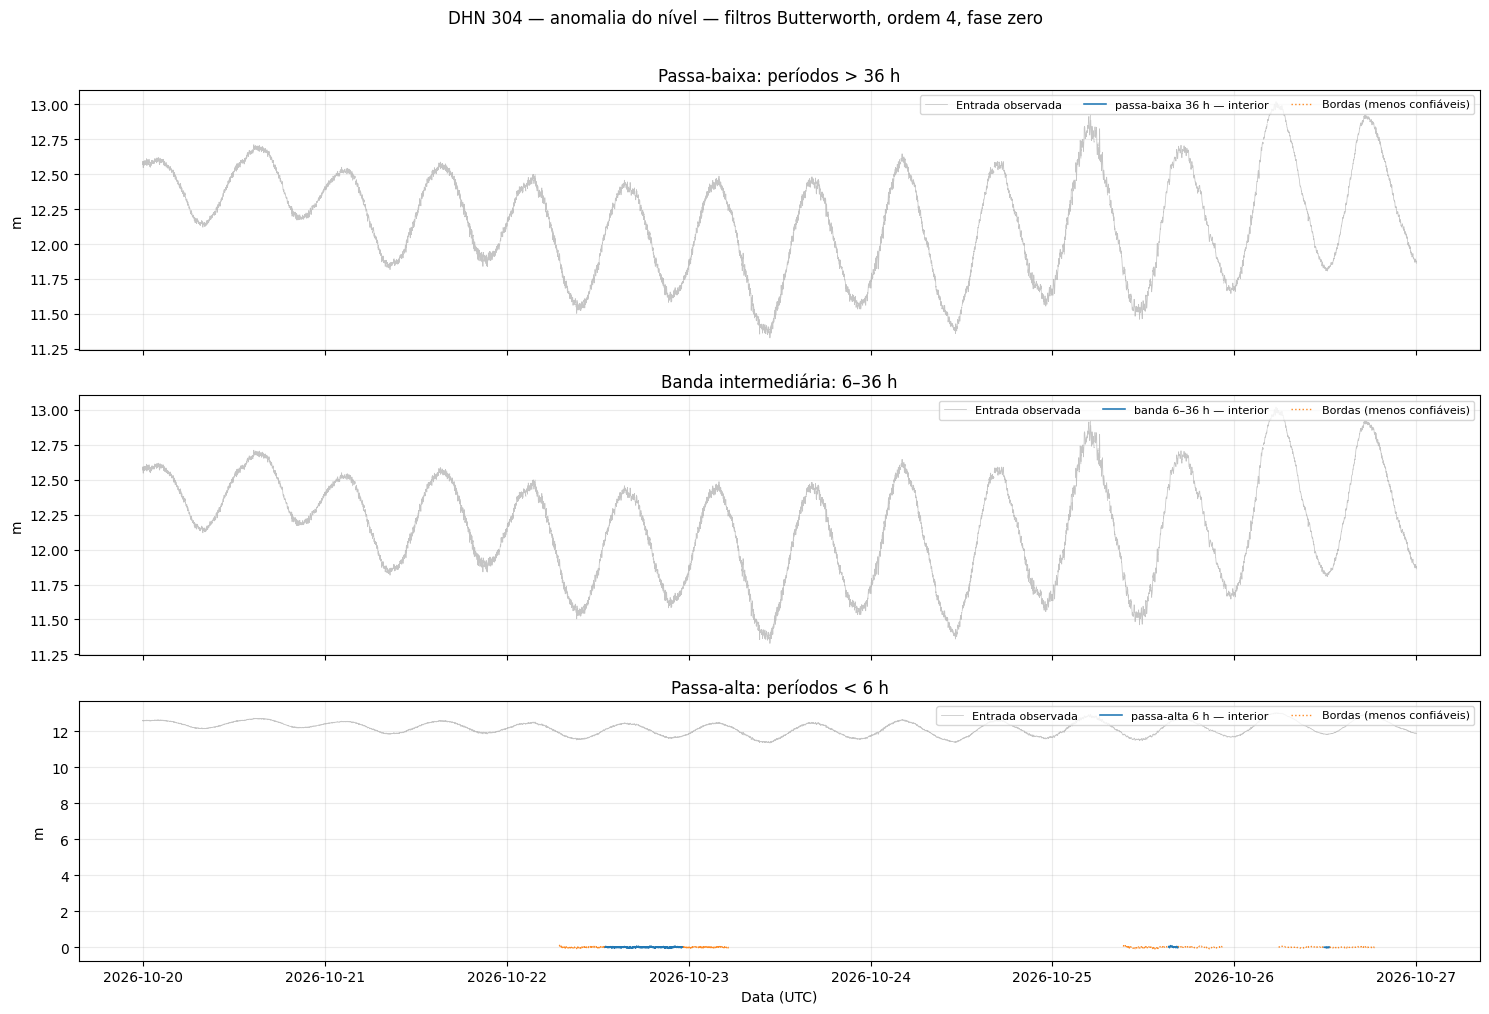

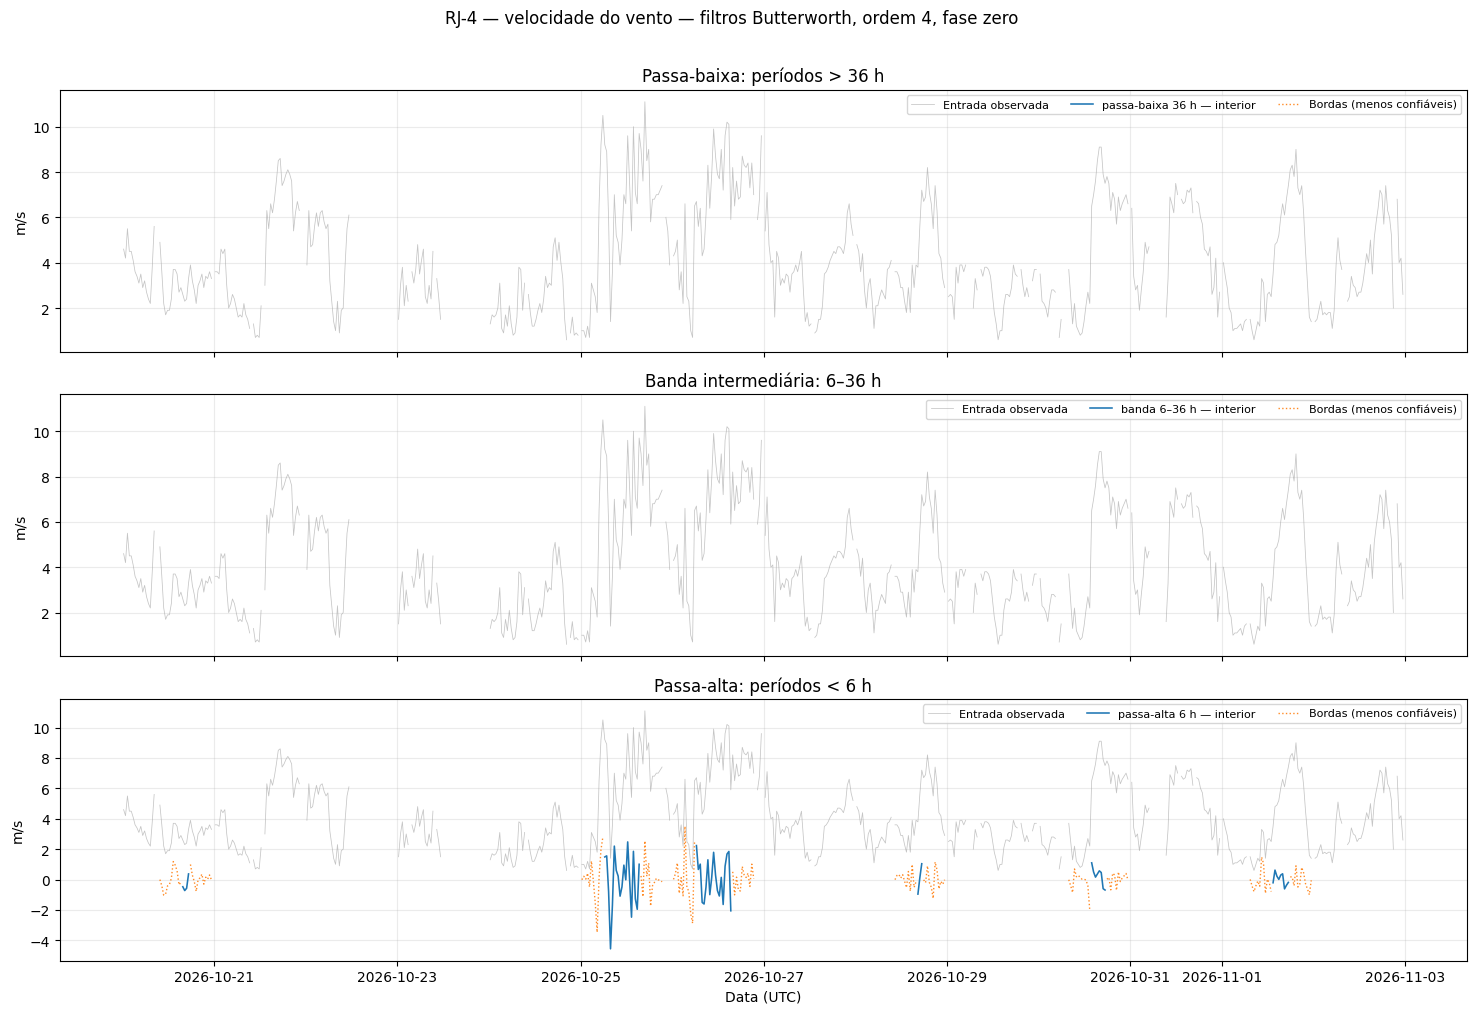

In [29]:
# 4.3 — Gráficos das três escalas; bordas tracejadas e lacunas/trechos curtos sem saída
def plotar_saidas_filtro(serie_entrada, resultado, titulo, unidade):
    fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
    especificacoes = [
        ("passa-baixa 36 h", "Passa-baixa: períodos > 36 h"),
        ("banda 6–36 h", "Banda intermediária: 6–36 h"),
        ("passa-alta 6 h", "Passa-alta: períodos < 6 h"),
    ]
    for ax, (col, rotulo) in zip(axes, especificacoes):
        ax.plot(serie_entrada.index, serie_entrada, color="0.65", lw=.55, alpha=.65, label="Entrada observada")
        borda = resultado[f"{col} — borda"]
        interior = resultado[col].where(~borda)
        bordas = resultado[col].where(borda)
        ax.plot(interior.index, interior, lw=1.15, label=f"{col} — interior")
        ax.plot(bordas.index, bordas, ls=":", lw=1.0, alpha=.9, label="Bordas (menos confiáveis)")
        ax.set_title(rotulo); ax.set_ylabel(unidade); ax.grid(alpha=.25); ax.legend(loc="upper right", ncol=3, fontsize=8)
    axes[-1].set_xlabel("Data (UTC)")
    fig.suptitle(f"{titulo} — filtros Butterworth, ordem 4, fase zero", y=1.01)
    fig.tight_layout(); plt.show()

plotar_saidas_filtro(nivel_obs, resultado_filtros_dhn, "DHN 304 — anomalia do nível", "m")
plotar_saidas_filtro(vento_obs, resultado_filtros_vento, "RJ-4 — velocidade do vento", "m/s")

In [30]:
# 4.4 — Variância de entrada e saída nos MESMOS pontos válidos e fora das bordas
def comparar_variancias_filtros(serie_entrada, resultado, nome_serie):
    linhas = []
    for col in ["passa-baixa 36 h", "banda 6–36 h", "passa-alta 6 h"]:
        borda = resultado[f"{col} — borda"]
        # Comparação pareada: entrada e saída disponíveis e saída fora da borda.
        mascara = serie_entrada.notna() & resultado[col].notna() & (~borda)
        x = serie_entrada.loc[mascara].astype(float)
        y = resultado.loc[mascara, col].astype(float)
        var_in = x.var(ddof=1) if len(x) > 1 else np.nan
        var_out = y.var(ddof=1) if len(y) > 1 else np.nan
        linhas.append({
            "Série": nome_serie, "Filtro": col, "N pareado (interior)": int(mascara.sum()),
            "Variância entrada": var_in, "Variância saída": var_out,
            "Razão saída/entrada": var_out / var_in if pd.notna(var_in) and var_in != 0 else np.nan,
            "Variância removida (%)": 100*(1-var_out/var_in) if pd.notna(var_in) and var_in != 0 else np.nan
        })
    return pd.DataFrame(linhas)

tabela_variancias_item4 = pd.concat([
    comparar_variancias_filtros(nivel_obs, resultado_filtros_dhn, "DHN 304"),
    comparar_variancias_filtros(vento_obs, resultado_filtros_vento, "RJ-4 vento")
], ignore_index=True)
print("Variâncias calculadas nos mesmos instantes válidos e fora das bordas:")
display(tabela_variancias_item4.round(6))

Variâncias calculadas nos mesmos instantes válidos e fora das bordas:


,Série,Filtro,N pareado (interior),Variância entrada,Variância saída,Razão saída/entrada,Variância removida (%)
0,DHN 304,passa-baixa 36 h,0,NaN,NaN,NaN,NaN
1,DHN 304,banda 6–36 h,0,NaN,NaN,NaN,NaN
2,DHN 304,passa-alta 6 h,737,0.100637,0.000436,0.004337,99.566328
3,RJ-4 vento,passa-baixa 36 h,0,NaN,NaN,NaN,NaN
4,RJ-4 vento,banda 6–36 h,0,NaN,NaN,NaN,NaN
5,RJ-4 vento,passa-alta 6 h,62,4.614524,1.626958,0.352573,64.742661


In [31]:
# 4.5 — Diagnóstico de lacunas, trechos curtos e bordas
def resumo_qualidade_filtros(serie, resultado, nome):
    linhas = []
    for col in ["passa-baixa 36 h", "banda 6–36 h", "passa-alta 6 h"]:
        linhas.append({
            "Série": nome, "Filtro": col,
            "Entrada válida": int(serie.notna().sum()),
            "Saída disponível (inclui bordas)": int(resultado[col].notna().sum()),
            "Pontos de borda": int(resultado[f"{col} — borda"].sum()),
            "Pontos em trechos curtos sem saída": int(resultado[f"{col} — trecho_curto"].sum()),
            "Saída interior confiável": int((resultado[col].notna() & ~resultado[f"{col} — borda"]).sum())
        })
    return pd.DataFrame(linhas)

qualidade_filtros_item4 = pd.concat([
    resumo_qualidade_filtros(nivel_obs, resultado_filtros_dhn, "DHN 304"),
    resumo_qualidade_filtros(vento_obs, resultado_filtros_vento, "RJ-4 vento")
], ignore_index=True)
display(qualidade_filtros_item4)

,Série,Filtro,Entrada válida,Saída disponível (inclui bordas),Pontos de borda,Pontos em trechos curtos sem saída,Saída interior confiável
0,DHN 304,passa-baixa 36 h,9990,0,0,9990,0
1,DHN 304,banda 6–36 h,9990,0,0,9990,0
2,DHN 304,passa-alta 6 h,9990,2897,2160,7093,737
3,RJ-4 vento,passa-baixa 36 h,576,0,0,576,0
4,RJ-4 vento,banda 6–36 h,576,0,0,576,0
5,RJ-4 vento,passa-alta 6 h,576,206,144,370,62


In [32]:
# 4.7 — Exportar saídas, variâncias e diagnóstico
resultado_filtros_dhn.to_csv("item4_filtros_DHN304.csv", encoding="utf-8-sig")
resultado_filtros_vento.to_csv("item4_filtros_RJ4_vento.csv", encoding="utf-8-sig")
tabela_variancias_item4.to_csv("item4_variancias_filtros.csv", index=False, encoding="utf-8-sig")
qualidade_filtros_item4.to_csv("item4_diagnostico_trechos_bordas.csv", index=False, encoding="utf-8-sig")
print("Arquivos CSV do item 4 exportados com sucesso.")

Arquivos CSV do item 4 exportados com sucesso.


In [33]:
# 5.1 — Cenários Q/R e períodos equivalentes de referência
# Q/R pequeno: modelo mais suave, maior atraso; Q/R grande: acompanha mais as observações.
# Valores intermediários explícitos para reproduzir os regimes rápido/base/lento dos slides.
CENARIOS_KALMAN = {
    "DHN 304": {
        "rápido": {"Tc_h": 0.17, "Q_R": 0.41},
        "base":   {"Tc_h": 2.0,  "Q_R": 0.010},
        "lento":  {"Tc_h": 36.0, "Q_R": 0.0001},
    },
    "RJ-4 vento": {
        "rápido": {"Tc_h": 1.0,  "Q_R": 21.0},
        "base":   {"Tc_h": 6.0,  "Q_R": 0.20},
        "lento":  {"Tc_h": 36.0, "Q_R": 0.008},
    },
}

tabela_qr = []
for nome, cenarios in CENARIOS_KALMAN.items():
    for cenario, pars in cenarios.items():
        tabela_qr.append({
            "série": nome, "cenário": cenario,
            "período equivalente de referência (h)": pars["Tc_h"],
            "Q/R adotado": pars["Q_R"]
        })
tabela_qr = pd.DataFrame(tabela_qr)
display(tabela_qr)

# Séries de entrada: anomalia do nível e anomalia do vento.
# Cada uma permanece com NaN nos timestamps sem observação.
serie_kalman_nivel = anomalia_nivel.astype(float)
serie_kalman_vento = (vento_obs - vento_obs.mean()).astype(float)



,série,cenário,período equivalente de referência (h),Q/R adotado
0,DHN 304,rápido,0.17,0.4100
1,DHN 304,base,2.00,0.0100
2,DHN 304,lento,36.00,0.0001
3,RJ-4 vento,rápido,1.00,21.0000
4,RJ-4 vento,base,6.00,0.2000
5,RJ-4 vento,lento,36.00,0.0080


In [35]:
# 5.2 — Estimar R e executar filtro causal + suavizador RTS
def estimar_R_diferencas(serie):
    """Estimativa robusta da variância do ruído de observação via diferenças de 1 passo.
    Usa somente pares consecutivos observados; R fica na unidade² da série.
    """
    s = serie.dropna().astype(float)
    if len(s) < 10:
        raise ValueError("Poucas observações para estimar R.")
    # Só diferenças entre timestamps adjacentes na grade, evitando saltos sobre lacunas.
    dif = s.diff()
    dt = s.index.to_series().diff()
    passo = s.index.to_series().diff().dropna().mode().iloc[0]
    dif = dif[(dt == passo)].dropna().to_numpy()
    if len(dif) < 5:
        raise ValueError("Poucos pares consecutivos para estimar R.")
    med = np.median(dif)
    sigma_dif = 1.4826 * np.median(np.abs(dif - med))
    R = max((sigma_dif ** 2) / 2.0, np.finfo(float).eps)
    return float(R), int(len(dif)), passo

def kalman_nivel_local_rts(serie, q_r):
    """Modelo local-level: x[t]=x[t-1]+w; y[t]=x[t]+v.
    Ausentes: somente previsão; observações originais: atualização.
    Retorna filtro causal, RTS, variâncias e máscara de observação.
    """
    s = serie.astype(float).sort_index()
    y = s.to_numpy()
    n = len(y)
    R, n_pares, passo = estimar_R_diferencas(s)
    Q = float(q_r) * R

    xf = np.full(n, np.nan)   # estado filtrado causal
    Pf = np.full(n, np.nan)   # variância posterior causal
    xp = np.full(n, np.nan)   # estado previsto antes da observação
    Pp = np.full(n, np.nan)   # variância prevista

    valid = np.flatnonzero(np.isfinite(y))
    if len(valid) == 0:
        raise ValueError("A série não possui observações.")
    primeiro = valid[0]
    x_prev = float(y[primeiro])
    P_prev = R  # incerteza inicial explícita

    for k in range(primeiro, n):
        # Modelo de passeio aleatório: F=1, portanto o estado previsto mantém o nível.
        if k == primeiro:
            x_pred, P_pred = x_prev, P_prev
        else:
            x_pred, P_pred = x_prev, P_prev + Q
        xp[k], Pp[k] = x_pred, P_pred

        if np.isfinite(y[k]):
            K = P_pred / (P_pred + R)
            x_post = x_pred + K * (y[k] - x_pred)
            P_post = (1.0 - K) * P_pred
        else:
            # Sem dado: não atualizar, apenas propagar a previsão e a incerteza.
            x_post, P_post = x_pred, P_pred

        xf[k], Pf[k] = x_post, max(P_post, 0.0)
        x_prev, P_prev = x_post, P_post

    # Suavização RTS retrospectiva. Só opera no intervalo a partir da primeira observação.
    xs = xf.copy()
    Ps = Pf.copy()
    for k in range(n - 2, primeiro - 1, -1):
        if not (np.isfinite(Pf[k]) and np.isfinite(Pp[k+1])):
            continue
        ganho = Pf[k] / Pp[k+1]  # F=1
        xs[k] = xf[k] + ganho * (xs[k+1] - xp[k+1])
        Ps[k] = Pf[k] + ganho**2 * (Ps[k+1] - Pp[k+1])
        Ps[k] = max(Ps[k], 0.0)

    saida = pd.DataFrame({
        "observacao": y,
        "causal": xf,
        "causal_sigma": np.sqrt(Pf),
        "RTS": xs,
        "RTS_sigma": np.sqrt(Ps),
        "observacao_original": np.isfinite(y)
    }, index=s.index)
    metadados = {
        "Q/R": float(q_r), "Q": Q, "R": R,
        "pares_consecutivos_R": n_pares, "passo": passo
    }
    return saida, metadados



In [36]:
# 5.3 — Rodar os três cenários para DHN 304 e RJ-4
resultados_kalman = {}
metadados_kalman = {}

for nome, serie in [
    ("DHN 304", serie_kalman_nivel),
    ("RJ-4 vento", serie_kalman_vento)
]:
    resultados_kalman[nome] = {}
    metadados_kalman[nome] = {}
    for cenario, pars in CENARIOS_KALMAN[nome].items():
        resultado, meta = kalman_nivel_local_rts(serie, pars["Q_R"])
        resultados_kalman[nome][cenario] = resultado
        metadados_kalman[nome][cenario] = meta

linhas_meta = []
for nome in metadados_kalman:
    for cenario, meta in metadados_kalman[nome].items():
        linhas_meta.append({
            "série": nome, "cenário": cenario,
            "período equivalente (h)": CENARIOS_KALMAN[nome][cenario]["Tc_h"],
            "Q/R": meta["Q/R"], "Q estimado": meta["Q"],
            "R estimado": meta["R"], "pares usados para R": meta["pares_consecutivos_R"]
        })
tabela_parametros_kalman = pd.DataFrame(linhas_meta)
display(tabela_parametros_kalman.round(8))



,série,cenário,período equivalente (h),Q/R,Q estimado,R estimado,pares usados para R
0,DHN 304,rápido,0.17,0.4100,4.506000e-05,0.000110,9899
1,DHN 304,base,2.00,0.0100,1.100000e-06,0.000110,9899
2,DHN 304,lento,36.00,0.0001,1.000000e-08,0.000110,9899
3,RJ-4 vento,rápido,1.00,21.0000,8.308828e+00,0.395659,535
4,RJ-4 vento,base,6.00,0.2000,7.913170e-02,0.395659,535
5,RJ-4 vento,lento,36.00,0.0080,3.165270e-03,0.395659,535


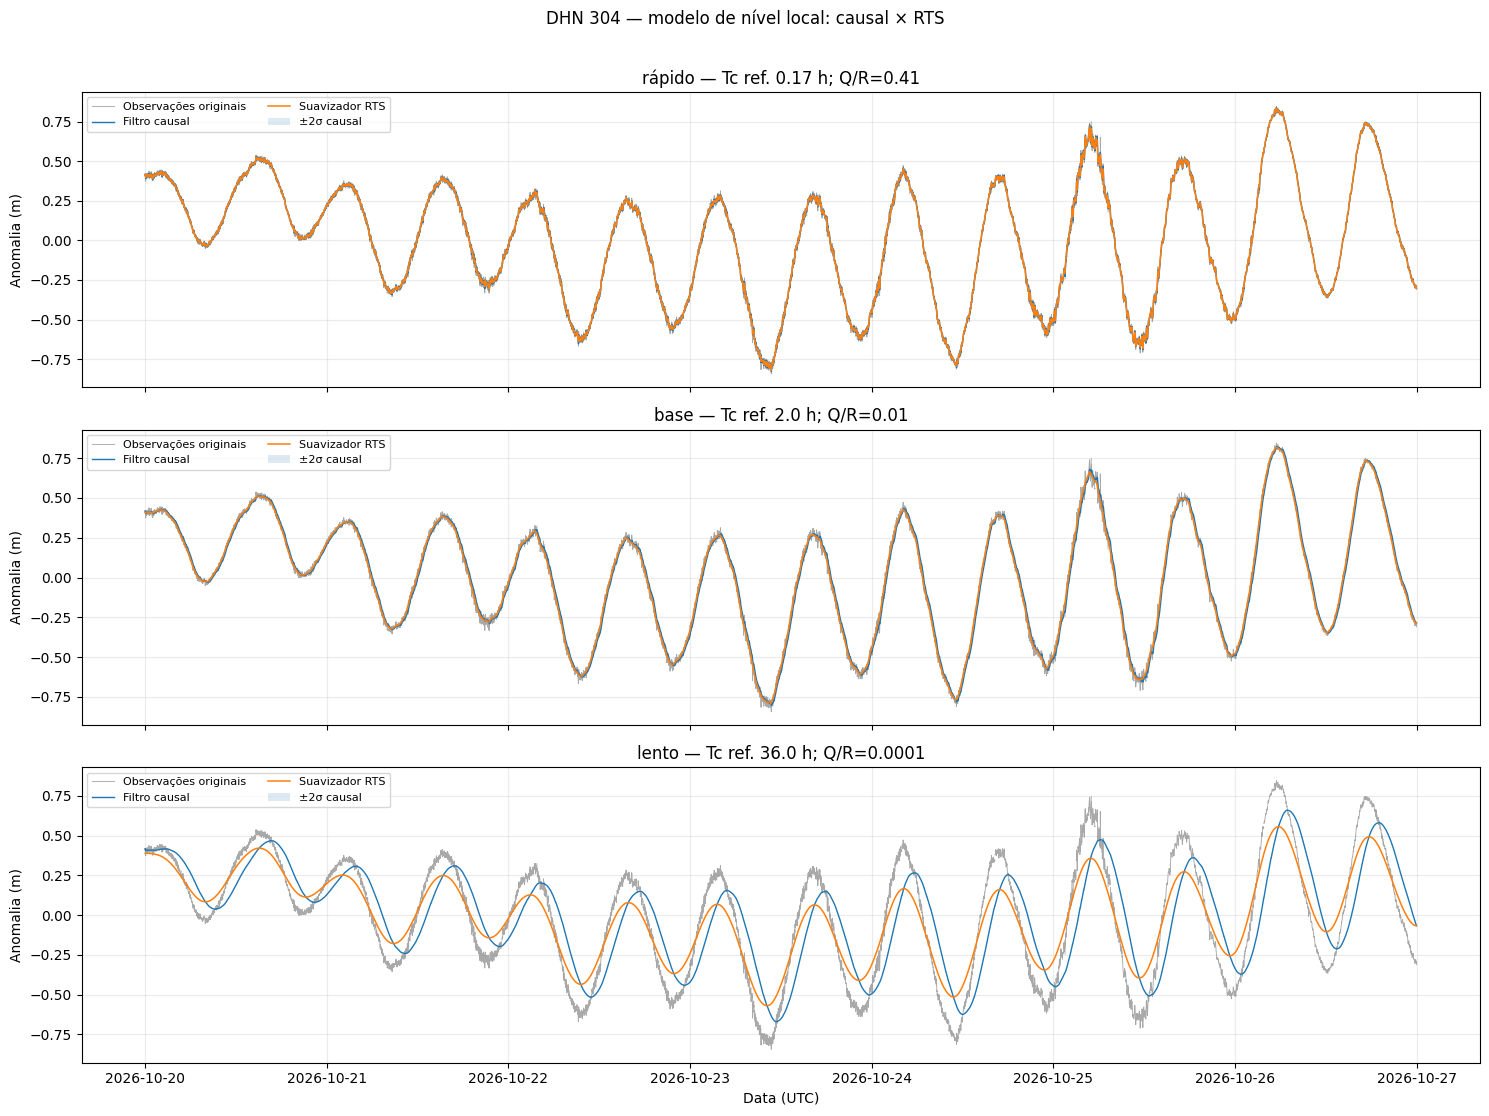

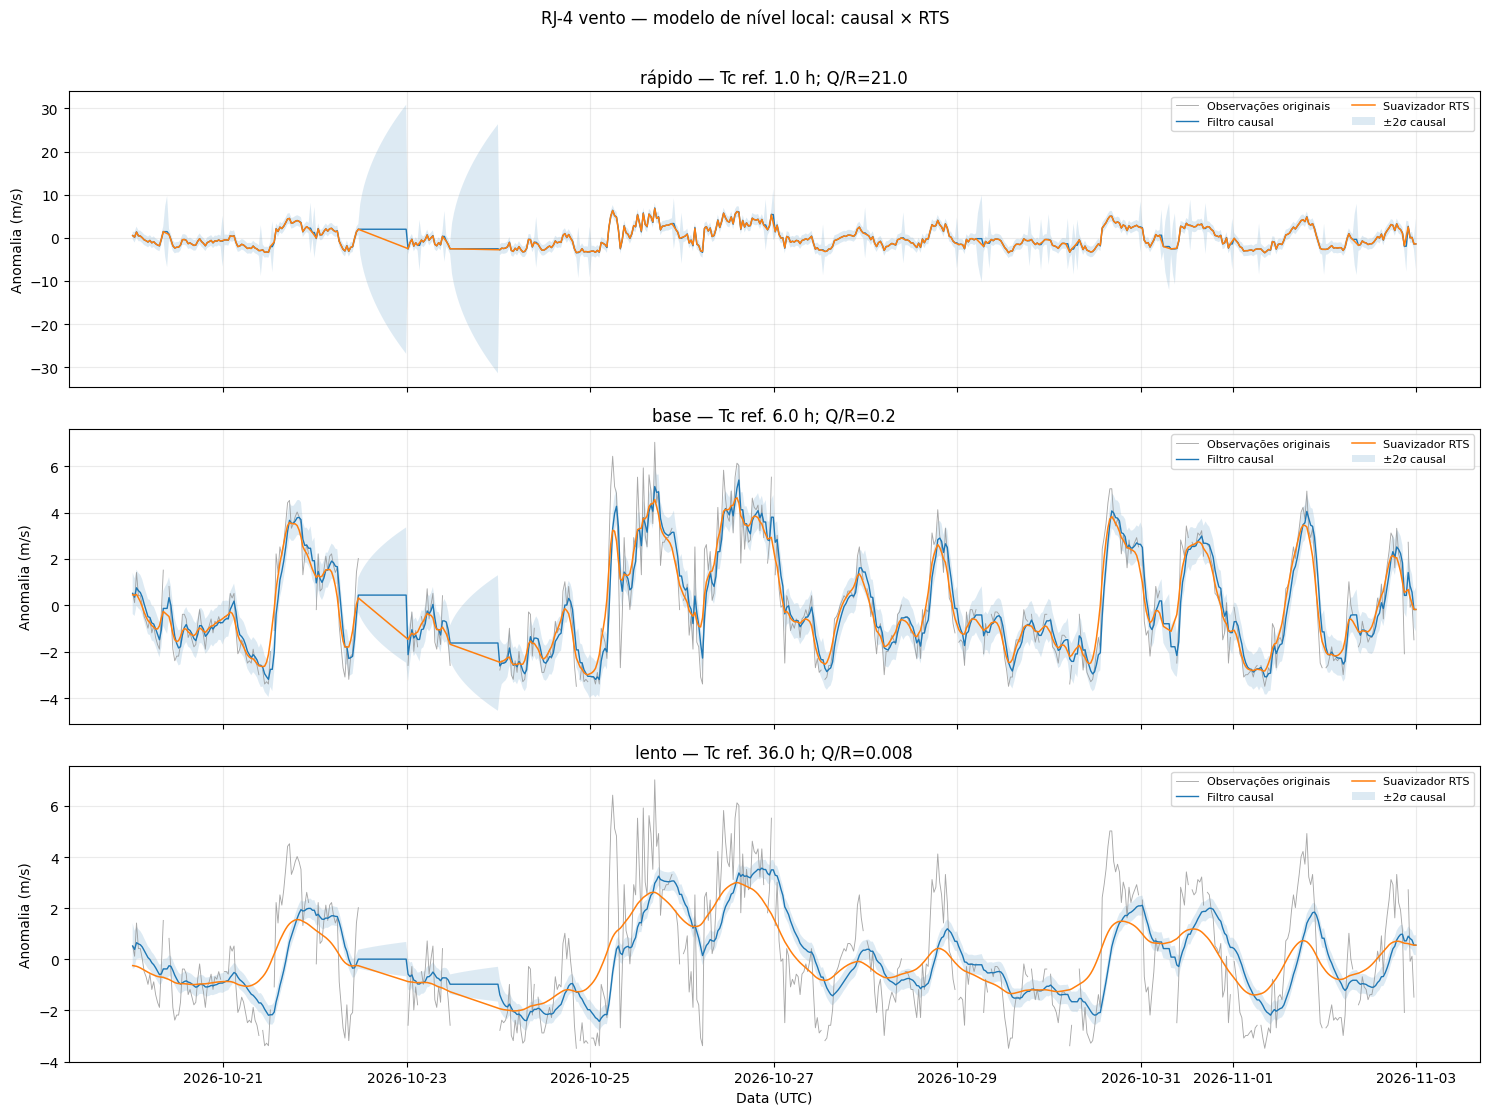

In [37]:
# 5.4 — Gráficos: filtro causal, RTS e faixa de incerteza ±2σ
def plotar_kalman(serie, resultados, titulo, unidade):
    fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
    for ax, (cenario, d) in zip(axes, resultados.items()):
        ax.plot(serie.index, serie, color="0.55", lw=0.65, alpha=0.75,
                label="Observações originais")
        ax.plot(d.index, d["causal"], lw=1.0, label="Filtro causal")
        ax.plot(d.index, d["RTS"], lw=1.1, label="Suavizador RTS")
        ax.fill_between(d.index, d["causal"]-2*d["causal_sigma"],
                        d["causal"]+2*d["causal_sigma"], alpha=0.15,
                        label="±2σ causal")
        ax.set_title(f"{cenario} — Tc ref. {CENARIOS_KALMAN[titulo][cenario]['Tc_h']} h; "
                     f"Q/R={CENARIOS_KALMAN[titulo][cenario]['Q_R']}")
        ax.set_ylabel(unidade)
        ax.grid(alpha=.25)
        ax.legend(loc="best", ncol=2, fontsize=8)
    axes[-1].set_xlabel("Data (UTC)")
    fig.suptitle(f"{titulo} — modelo de nível local: causal × RTS", y=1.01)
    plt.tight_layout()
    plt.show()

plotar_kalman(serie_kalman_nivel, resultados_kalman["DHN 304"], "DHN 304", "Anomalia (m)")
plotar_kalman(serie_kalman_vento, resultados_kalman["RJ-4 vento"], "RJ-4 vento", "Anomalia (m/s)")



In [38]:
# 5.5 — Diagnóstico do atraso causal em relação ao RTS e à observação
def estimar_atraso_h(serie, estimativa, passo, max_atraso_h):
    """Atraso positivo significa que a estimativa acompanha a observação com atraso.
    Estima por correlação cruzada em pontos observados e alinhados na grade.
    """
    y = serie.to_numpy(dtype=float)
    x = estimativa.to_numpy(dtype=float)
    max_lag = max(1, int(round(max_atraso_h / (passo.total_seconds()/3600))))
    candidatos = []
    for lag in range(-max_lag, max_lag+1):
        if lag > 0:
            a, b = x[:-lag], y[lag:]
        elif lag < 0:
            a, b = x[-lag:], y[:lag]
        else:
            a, b = x, y
        m = np.isfinite(a) & np.isfinite(b)
        if m.sum() < 10:
            continue
        aa, bb = a[m], b[m]
        if np.std(aa) == 0 or np.std(bb) == 0:
            continue
        corr = np.corrcoef(aa, bb)[0,1]
        candidatos.append((corr, lag))
    if not candidatos:
        return np.nan, np.nan
    corr, lag = max(candidatos, key=lambda z: z[0])
    return lag * passo.total_seconds()/3600.0, corr

linhas_atraso = []
for nome, serie in [("DHN 304", serie_kalman_nivel), ("RJ-4 vento", serie_kalman_vento)]:
    passo = serie.index.to_series().diff().dropna().mode().iloc[0]
    for cenario, d in resultados_kalman[nome].items():
        atraso, corr = estimar_atraso_h(serie, d["causal"], passo, max_atraso_h=48)
        atraso_rts, corr_rts = estimar_atraso_h(serie, d["RTS"], passo, max_atraso_h=48)
        linhas_atraso.append({
            "série": nome, "cenário": cenario,
            "atraso causal estimado (h)": atraso,
            "correlação causal máxima": corr,
            "atraso RTS estimado (h)": atraso_rts,
            "correlação RTS máxima": corr_rts
        })
tabela_atrasos_kalman = pd.DataFrame(linhas_atraso)
display(tabela_atrasos_kalman.round(3))



,série,cenário,atraso causal estimado (h),correlação causal máxima,atraso RTS estimado (h),correlação RTS máxima
0,DHN 304,rápido,0.000,1.000,0.000,1.000
1,DHN 304,base,-0.150,0.999,0.000,0.999
2,DHN 304,lento,-1.383,0.991,-0.017,0.967
3,RJ-4 vento,rápido,0.000,1.000,0.000,1.000
4,RJ-4 vento,base,-0.500,0.947,0.000,0.942
5,RJ-4 vento,lento,-2.500,0.831,0.000,0.776


Maior lacuna RJ-4: 2026-10-22 11:51:00+00:00 até 2026-10-22 23:51:00+00:00 | 25 amostras ausentes


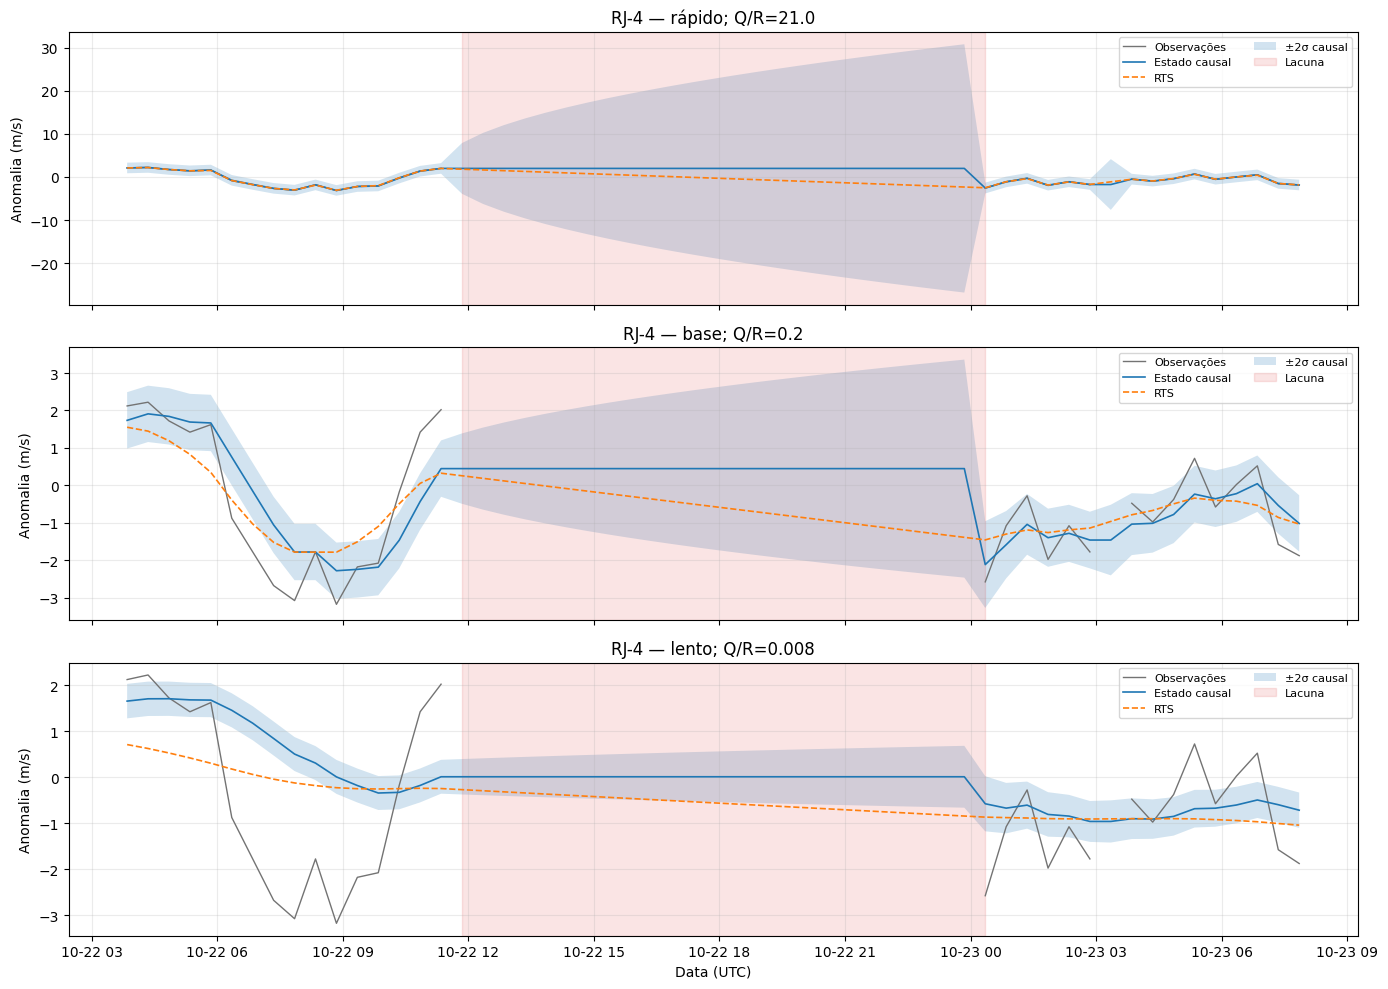

In [39]:
# 5.6 — Destacar a maior lacuna do vento e a evolução da incerteza
def maior_lacuna(serie):
    aus = serie.isna()
    grupos = aus.ne(aus.shift()).cumsum()
    blocos = []
    for _, trecho in serie[aus].groupby(grupos[aus]):
        blocos.append((trecho.index[0], trecho.index[-1], len(trecho)))
    if not blocos:
        return None
    return max(blocos, key=lambda x: x[2])

lacuna_vento = maior_lacuna(serie_kalman_vento)
if lacuna_vento is not None:
    t_ini, t_fim, n_lac = lacuna_vento
    print(f"Maior lacuna RJ-4: {t_ini} até {t_fim} | {n_lac} amostras ausentes")
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for ax, (cenario, d) in zip(axes, resultados_kalman["RJ-4 vento"].items()):
        janela = (d.index >= t_ini - pd.Timedelta(hours=8)) & (d.index <= t_fim + pd.Timedelta(hours=8))
        dj = d.loc[janela]
        ax.plot(dj.index, dj["observacao"], color="0.45", lw=1, label="Observações")
        ax.plot(dj.index, dj["causal"], lw=1.2, label="Estado causal")
        ax.plot(dj.index, dj["RTS"], lw=1.2, ls="--", label="RTS")
        ax.fill_between(dj.index, dj["causal"]-2*dj["causal_sigma"],
                        dj["causal"]+2*dj["causal_sigma"], alpha=.2, label="±2σ causal")
        ax.axvspan(t_ini, t_fim + serie_kalman_vento.index.to_series().diff().dropna().mode().iloc[0],
                   color="tab:red", alpha=.12, label="Lacuna")
        ax.set_title(f"RJ-4 — {cenario}; Q/R={CENARIOS_KALMAN['RJ-4 vento'][cenario]['Q_R']}")
        ax.set_ylabel("Anomalia (m/s)")
        ax.grid(alpha=.25); ax.legend(fontsize=8, ncol=2)
    axes[-1].set_xlabel("Data (UTC)")
    plt.tight_layout(); plt.show()
else:
    print("Não há lacunas na série de vento.")



In [40]:
# 5.7 — Exportar resultados do filtro de Kalman/RTS
for nome, resultados in resultados_kalman.items():
    prefixo = "DHN304" if nome == "DHN 304" else "RJ4_vento"
    for cenario, d in resultados.items():
        d.to_csv(f"item5_kalman_{prefixo}_{cenario}.csv", encoding="utf-8-sig")

tabela_parametros_kalman.to_csv("item5_parametros_QR.csv", index=False, encoding="utf-8-sig")
tabela_atrasos_kalman.to_csv("item5_atrasos.csv", index=False, encoding="utf-8-sig")
print("Arquivos CSV do item 5 exportados.")


Arquivos CSV do item 5 exportados.
